# Design B3 à 1,00 GHz — présentation

Synthèse du design retenu pour le *First EurAAP Small Antenna Super-Gain Challenge* : géométrie, maillage, courants,
diagramme, performances en fréquence, robustesse et validation du solveur.
Toutes les valeurs affichées sont **lues dans les fichiers de résultats** (`fiches_cst/resultats_V6/`, `exploration/`,
`fiches_cst/resultats_V5/`), sauf le statut CST de la section 11, tenu à la main.
Une seule simulation MoM est lancée (section 3, ≈ 1 min de GPU), pour les courants et le diagramme 3D.
Les figures sont aussi enregistrées en PNG dans `presentation/figures/`.

In [1]:
%matplotlib inline
import csv, json, os, re, shutil, sys, time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle
import plotly.graph_objects as go
import plotly.io as pio
from IPython.display import Image, Markdown, display

T_START = time.perf_counter()
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'solver' / 'optim').is_dir())
HERE = ROOT / 'solver' / 'antenna_simulation' / 'euraap_challenge'
for p in (str(ROOT), str(HERE)):
    if p not in sys.path:
        sys.path.insert(0, p)

BASE = Path(os.environ.get('CHALLENGE_DIR',
                           r'D:\PhD_Fahdilou_Leat\PUBLICATIONS\7-EurAAP Small Antenna Super-Gain Challenge'))
V6_DIR, V5_DIR = BASE / 'fiches_cst' / 'resultats_V6', BASE / 'fiches_cst' / 'resultats_V5'
EXPL_DIR, NOTES_DIR, INSTR_DIR = BASE / 'exploration', BASE / 'notes_comprehension', BASE / 'instructions_claude_code'
FIG_DIR = BASE / 'presentation' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAG = 'B3_1.00GHz'


def read_json(p):
    return json.loads(Path(p).read_text(encoding='utf-8'))


def read_jsonl(p):
    return [json.loads(l) for l in open(p, encoding='utf-8') if l.strip()]


def read_csv(p):
    def num(v):
        try:
            return float(v)
        except ValueError:
            return {'True': True, 'False': False}.get(v, v)
    with open(p, newline='', encoding='utf-8') as fh:
        return [{k: num(v) for k, v in r.items()} for r in csv.DictReader(fh)]


PARAMS = read_json(V6_DIR / f'V6_parametres_{TAG}.json')
ADAPT = read_json(V6_DIR / f'V6_adaptation_{TAG}.json')
FREQ = read_csv(V6_DIR / f'V6_expected_{TAG}_freq.csv')
CUT_XY = read_csv(V6_DIR / f'V6_expected_{TAG}_cut_theta90_xy.csv')
CUT_YZ = read_csv(V6_DIR / f'V6_expected_{TAG}_cut_phi90_yz.csv')
B3 = read_jsonl(EXPL_DIR / 'B3_designs.jsonl')
B4 = read_jsonl(EXPL_DIR / 'B4_designs.jsonl')
B4_HIST = read_json(EXPL_DIR / 'B4_bo_history.json')
CAMP_CHECKS = {c: read_json(EXPL_DIR / f'{c}_checks.json') for c in ('B3', 'B4')}
A2 = read_csv(EXPL_DIR / 'sweepA_w4mm.csv')
F0 = PARAMS['f0_GHz'] * 1e9
print(f"design {PARAMS['campaign']} (généré {PARAMS['generated']}, commit {PARAMS['git']['commit'][:7]}), "
      f"adaptation générée {ADAPT['generated']}")
print(f'{len(FREQ)} fréquences, coupes {len(CUT_XY)} + {len(CUT_YZ)} points | B3 {len(B3)} enregistrements, '
      f"B4 {len(B4)}, balayage A {len(A2)} lignes")

# --- coherence log (section 12) ---------------------------------------------------------------------
COHERENCE = []


def check(name, a, b, tol, unit=''):
    # Compare two values read from two sources; logged for the summary of section 12.
    d = float(np.max(np.abs(np.asarray(a, dtype=complex) - np.asarray(b, dtype=complex))))
    COHERENCE.append(dict(name=name, a=a, b=b, diff=d, tol=tol, unit=unit, ok=bool(d <= tol)))
    return d <= tol


# --- figure style: palette of the euraap_challenge notebooks ----------------------------------------
INK, INK_2, MUTED, GRID, AXIS, SURFACE = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#fcfcfb'
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
COPPER = '#b87333'
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
                     'axes.edgecolor': AXIS, 'axes.labelcolor': INK_2, 'xtick.color': MUTED, 'ytick.color': MUTED,
                     'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.spines.top': False,
                     'axes.spines.right': False, 'lines.linewidth': 1.6, 'legend.frameon': False,
                     'font.size': 9, 'axes.titlesize': 10, 'figure.dpi': 110})
pio.renderers.default = 'plotly_mimetype+png'      # interactive in VS Code / Jupyter, static PNG elsewhere
FIGURES = []


def save(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches='tight')
    FIGURES.append(name)
    plt.show()


def save_plotly(fig, name, width=900, height=650):
    fig.write_image(FIG_DIR / name, width=width, height=height, scale=2)
    FIGURES.append(name)
    fig.show(width=width, height=height)


def md_table(headers, rows):
    lines = ['| ' + ' | '.join(headers) + ' |', '|' + '---|' * len(headers)]
    lines += ['| ' + ' | '.join(str(c) for c in r) + ' |' for r in rows]
    display(Markdown('\n'.join(lines)))


def db(x):
    return 10 * np.log10(np.asarray(x, float))


def fr(x, n=2):
    # French decimal comma for the text cells
    return f'{x:.{n}f}'.replace('.', ',')

design B3_1.00GHz (généré 2026-11-05T16:57:45, commit aeb951d), adaptation générée 2026-11-06T11:09:55
9 fréquences, coupes 360 + 181 points | B3 270 enregistrements, B4 180, balayage A 198 lignes


## 1. Le challenge en bref

L'antenne doit tenir dans une boîte de 187 × 125 × 5 mm et fonctionner à une fréquence choisie dans 0,8–1 GHz,
avec **un seul port 50 Ω**. On maximise le **gain réalisé** en end-fire selon **+y**, en polarisation **φ** :
en +y, $\hat{\varphi} = -\hat{x}$, donc les courants utiles sont orientés selon x.
Les valeurs ci-dessous sont lues dans `notes_comprehension/01_sujet_et_contraintes.md`.

| Contrainte | Valeur |
|---|---|
| Boîte (x × y × z) | 187 × 125 × 5 mm |
| Fréquence f₀ | au choix dans [0,8 ; 1] GHz — retenue : **1,00 GHz** |
| Alimentation | **un seul port**, 50 Ω, SMA |
| Objectif | maximiser le **gain réalisé** en end-fire selon **+y**, polarisation **φ** |
| Date limite du rapport | 10 novembre 2026 |

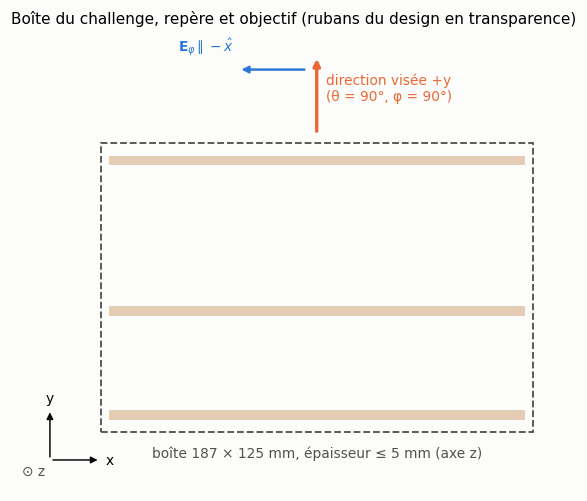

In [2]:
spec = (NOTES_DIR / '01_sujet_et_contraintes.md').read_text(encoding='utf-8')


def grab(pattern):
    m = re.search(pattern, spec)
    if m is None:
        raise ValueError(f'motif introuvable dans 01_sujet_et_contraintes.md : {pattern}')
    return m.group(1)


W_BOX = float(grab(r'Largeur \$W\$ \(axe x\) \| ≤ (\d+) mm'))
L_BOX = float(grab(r'Longueur \$L\$ \(axe y\) \| ≤ (\d+) mm'))
H_BOX = float(grab(r'Hauteur \$H\$ \(axe z\) \| ≤ (\d+) mm'))
F_LO, F_HI = (float(v.replace(',', '.')) for v in re.search(r'dans \[(\d+(?:,\d+)?) ; (\d+(?:,\d+)?)\] GHz', spec).groups())
DEADLINE = grab(r'Date limite du rapport : \*\*([^*]+)\*\*')
md_table(['Contrainte', 'Valeur'], [
    ['Boîte (x × y × z)', f'{W_BOX:g} × {L_BOX:g} × {H_BOX:g} mm'],
    ['Fréquence f₀', f'au choix dans [{fr(F_LO, 1)} ; {fr(F_HI, 0)}] GHz — retenue : **{fr(F0 / 1e9)} GHz**'],
    ['Alimentation', grab(r'\| Alimentation \| (.+?) \|')],
    ['Objectif', grab(r'\| Objectif \| (.+?) \|')],
    ['Date limite du rapport', DEADLINE],
])

fig, ax = plt.subplots(figsize=(7.2, 5.4))
ax.add_patch(Rectangle((-W_BOX / 2, -L_BOX / 2), W_BOX, L_BOX, fill=False, ls='--', lw=1.2, ec=INK_2))
for s in PARAMS['strips']:
    (x0, x1), (y0, y1) = s['x_extent_mm']['value'], s['y_edges_mm']['value']
    ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, color=COPPER, alpha=0.35, lw=0))
ax.annotate('', xy=(0, L_BOX / 2 + 38), xytext=(0, L_BOX / 2 + 4),
            arrowprops=dict(arrowstyle='-|>', lw=2.2, color=SERIES[1]))
ax.text(4, L_BOX / 2 + 24, 'direction visée +y\n(θ = 90°, φ = 90°)', color=SERIES[1], va='center')
ax.annotate('', xy=(-34, L_BOX / 2 + 32), xytext=(-4, L_BOX / 2 + 32),
            arrowprops=dict(arrowstyle='-|>', lw=1.6, color=SERIES[0]))
ax.text(-36, L_BOX / 2 + 40, r'$\mathbf{E}_\varphi \parallel -\hat{x}$', color=SERIES[0], ha='right')
ox, oy = -W_BOX / 2 - 22, -L_BOX / 2 - 12
ax.annotate('', xy=(ox + 22, oy), xytext=(ox, oy), arrowprops=dict(arrowstyle='-|>', color=INK))
ax.annotate('', xy=(ox, oy + 22), xytext=(ox, oy), arrowprops=dict(arrowstyle='-|>', color=INK))
ax.text(ox + 24, oy, 'x', va='center'); ax.text(ox, oy + 25, 'y', ha='center')
ax.text(ox - 2, oy - 2, '⊙ z', ha='right', va='top', color=INK_2)
ax.text(0, -L_BOX / 2 - 6, f'boîte {W_BOX:g} × {L_BOX:g} mm, épaisseur ≤ {H_BOX:g} mm (axe z)',
        ha='center', va='top', color=INK_2)
ax.set_xlim(-W_BOX / 2 - 30, W_BOX / 2 + 10); ax.set_ylim(-L_BOX / 2 - 25, L_BOX / 2 + 48)
ax.set_aspect('equal'); ax.axis('off')
ax.set_title('Boîte du challenge, repère et objectif (rubans du design en transparence)')
save(fig, '01_challenge_boite_repere.png')

## 2. Le design retenu

Trois rubans de cuivre parallèles à x, empilés selon y dans le plan z = 0. Le ruban central (el2) est alimenté
en son milieu ; les deux autres sont chargés en leur milieu par une capacité du kit Johanson.
La figure et le tableau sont construits à partir de `V6_parametres_B3_1.00GHz.json` ; les cotes
(bords et centres) sont recontrôlées à la fin de la cellule.

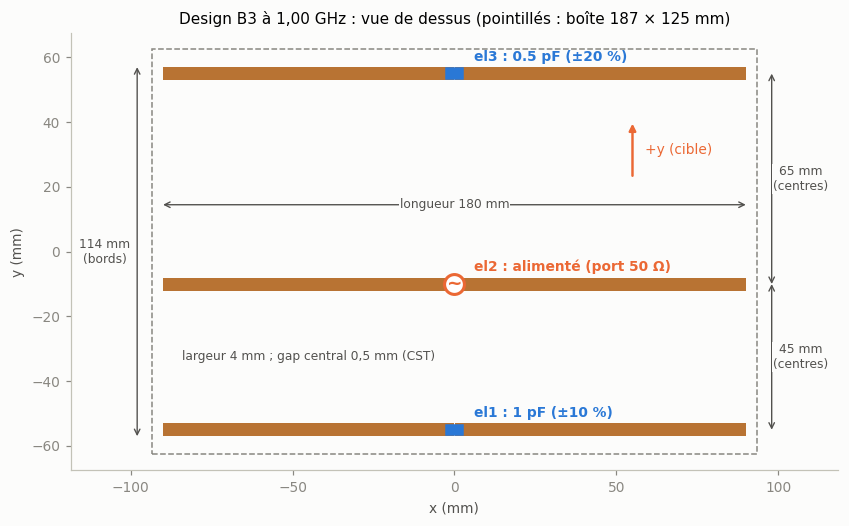

| ruban | rôle | y centre (mm) | y bords (mm) | x bords (mm) | largeur (mm) | longueur (mm) | composant au gap |
|---|---|---|---|---|---|---|---|
| el1 | chargé | -55.00 | -57.00 / -53.00 | -90 / 90 | 4 | 180 | 1 pF ±10 % (Johanson S603DS), X* continu = -159.9 Ω |
| el2 | alimenté | -10.00 | -12.00 / -8.00 | -90 / 90 | 4 | 180 | — |
| el3 | chargé | 55.00 | 53.00 / 57.00 | -90 / 90 | 4 | 180 | 0.5 pF ±20 % (Johanson S603DS), X* continu = -315.3 Ω |

Écarts centre à centre : **45 / 65 mm** ; encombrement bord à bord selon y : **114 mm** ; matériau : cuivre σ = 5.80e+07 S/m, 35 µm (modèle MoM : sheet + alpha_cal Zs, α_cal = 1.09).

dans la boîte : True (marges : 7 mm en x, 11 mm en y)


In [3]:
strips = PARAMS['strips']
gap_cst = float(re.search(r'CST: ([\d.]+) mm gap', strips[0]['gap']).group(1))
fed_name = PARAMS['fed_port']['strip']
yc = np.array([s['y_center_mm']['value'] for s in strips])
w_mm = strips[0]['width_mm']
L_mm = strips[0]['length_mm']

fig, ax = plt.subplots(figsize=(9, 6.2))
ax.add_patch(Rectangle((-W_BOX / 2, -L_BOX / 2), W_BOX, L_BOX, fill=False, ls='--', lw=1.0, ec=MUTED))
for s in strips:
    (x0, x1), (y0, y1) = s['x_extent_mm']['value'], s['y_edges_mm']['value']
    for a, b in ((x0, -gap_cst / 2), (gap_cst / 2, x1)):
        ax.add_patch(Rectangle((a, y0), b - a, y1 - y0, color=COPPER, lw=0))
    yc_s = s['y_center_mm']['value']
    if s['name'] == fed_name:
        ax.plot(0, yc_s, 'o', ms=13, mfc='white', mec=SERIES[1], mew=2)
        ax.text(0, yc_s, '~', ha='center', va='center', color=SERIES[1], fontsize=12, fontweight='bold')
        ax.text(6, yc_s + 4, f"{s['name']} : alimenté (port {PARAMS['fed_port']['generator_ohm']:g} Ω)",
                color=SERIES[1], fontweight='bold')
    else:
        c = s['component']
        ax.add_patch(Rectangle((-2.5, yc_s - 1.6), 5, 3.2, color=SERIES[0], zorder=3))
        ax.text(6, yc_s + 4, f"{s['name']} : {c['label']} (±{100 * c['tolerance_rel']:.0f} %)",
                color=SERIES[0], fontweight='bold')


def dim(p, q, text, off=(0, 0), **kw):
    ax.annotate('', xy=q, xytext=p, arrowprops=dict(arrowstyle='<->', color=INK_2, lw=0.9, shrinkA=0, shrinkB=0))
    ax.text((p[0] + q[0]) / 2 + off[0], (p[1] + q[1]) / 2 + off[1], text, color=INK_2, ha='center', va='center',
            fontsize=8, bbox=dict(fc=SURFACE, ec='none', pad=0.5), **kw)


x_dim = strips[0]['x_extent_mm']['value'][1] + 8
dim((x_dim, yc[0]), (x_dim, yc[1]), f"{PARAMS['spacings_mm']['value'][0]:g} mm\n(centres)", off=(9, 0))
dim((x_dim, yc[1]), (x_dim, yc[2]), f"{PARAMS['spacings_mm']['value'][1]:g} mm\n(centres)", off=(9, 0))
y_lo, y_hi = strips[0]['y_edges_mm']['value'][0], strips[-1]['y_edges_mm']['value'][1]
x_ext = strips[0]['x_extent_mm']['value'][0] - 8
dim((x_ext, y_lo), (x_ext, y_hi), f"{PARAMS['extent_mm']['value']:g} mm\n(bords)", off=(-10, 0))
y_len = 0.5 * (yc[1] + yc[2]) - 8
dim((strips[-1]['x_extent_mm']['value'][0], y_len), (strips[-1]['x_extent_mm']['value'][1], y_len),
    f'longueur {L_mm:g} mm')
ax.text(-45, 0.5 * (yc[0] + yc[1]), f"largeur {w_mm:g} mm ; gap central {fr(gap_cst, 1)} mm (CST)",
        color=INK_2, fontsize=8, ha='center', va='center')
ax.annotate('', xy=(55, y_len + 26), xytext=(55, y_len + 8), arrowprops=dict(arrowstyle='-|>', color=SERIES[1], lw=1.6))
ax.text(59, y_len + 17, '+y (cible)', color=SERIES[1], va='center')
ax.set_xlim(-W_BOX / 2 - 25, W_BOX / 2 + 25); ax.set_ylim(-L_BOX / 2 - 5, L_BOX / 2 + 5)
ax.set_aspect('equal'); ax.set_xlabel('x (mm)'); ax.set_ylabel('y (mm)'); ax.grid(False)
ax.set_title(f"Design B3 à {fr(F0 / 1e9)} GHz : vue de dessus (pointillés : boîte {W_BOX:g} × {L_BOX:g} mm)")
save(fig, '02_design_vue_dessus_cotes.png')

rows = []
for s in strips:
    c = s['component']
    rows.append([s['name'], {'fed': 'alimenté', 'loaded': 'chargé'}[s['role']], f"{s['y_center_mm']['value']:.2f}",
                 ' / '.join(f'{v:.2f}' for v in s['y_edges_mm']['value']),
                 ' / '.join(f'{v:g}' for v in s['x_extent_mm']['value']), f"{s['width_mm']:g}", f"{s['length_mm']:g}",
                 '—' if c is None else f"{c['label']} ±{100 * c['tolerance_rel']:.0f} % ({c['kit']}), "
                                       f"X* continu = {c['x_continuous_ohm']:.1f} Ω"])
md_table(['ruban', 'rôle', 'y centre (mm)', 'y bords (mm)', 'x bords (mm)', 'largeur (mm)', 'longueur (mm)',
          'composant au gap'], rows)
display(Markdown(f"Écarts centre à centre : **{' / '.join(f'{d:g}' for d in PARAMS['spacings_mm']['value'])} mm** ; "
                 f"encombrement bord à bord selon y : **{PARAMS['extent_mm']['value']:g} mm** ; "
                 f"matériau : cuivre σ = {PARAMS['material']['sigma_S_per_m']:.2e} S/m, "
                 f"{PARAMS['material']['thickness_um']} µm (modèle MoM : {PARAMS['material']['model']}, "
                 f"α_cal = {PARAMS['material']['alpha_cal']})."))

# cotes: edges vs centres, spacings, extent, x extent
for s in strips:
    yc_s, (e0, e1) = s['y_center_mm']['value'], s['y_edges_mm']['value']
    check(f"{s['name']} : bords y = centre ± largeur/2", [e0, e1], [yc_s - s['width_mm'] / 2, yc_s + s['width_mm'] / 2], 1e-9, 'mm')
    check(f"{s['name']} : bords x = ± longueur/2", s['x_extent_mm']['value'], [-s['length_mm'] / 2, s['length_mm'] / 2], 1e-9, 'mm')
check('écarts JSON = différences des centres', PARAMS['spacings_mm']['value'], np.diff(yc), 1e-9, 'mm')
check('encombrement JSON = bord haut el3 − bord bas el1', PARAMS['extent_mm']['value'], y_hi - y_lo, 1e-9, 'mm')
check('réseau centré en y (centre des bords extrêmes = 0)', (y_hi + y_lo) / 2, 0.0, 1e-9, 'mm')
print('dans la boîte :', L_mm <= W_BOX and PARAMS['extent_mm']['value'] <= L_BOX,
      f'(marges : {W_BOX - L_mm:g} mm en x, {L_BOX - PARAMS["extent_mm"]["value"]:g} mm en y)')

## 3. Simulation MoM à f₀ et maillage RWG

**Seule simulation du notebook.** La cellule suivante reconstruit le maillage exactement comme la campagne B3
(`campaign_b.build_mesh`), remplit Z à f₀ (mode `full_sym`), construit le modèle multiport réduit à 3 ports
(pertes cuivre avec α_cal) et résout avec les capacités du kit (ESR = ESL = 0, comme le nominal du JSON).
Durée estimée affichée avant le calcul (≈ 1 min sur le GPU du portable) ; le résultat sert aux sections 3, 4, 5 et 10.

In [4]:
# ======================  SIMULATION MoM (seul calcul lourd du notebook)  ======================
import campaign_b as cb
import v5_mom_runs as v5
from solver.optim.components import IDEAL, JOHANSON_S603DS, series_impedance
from solver.optim.design_eval import BACK, DIRECTION, DesignContext
from solver.utils.impmet import DEFAULT_FILL_MODE, rwg_gram_matrix

spacings_m = [d * 1e-3 for d in PARAMS['spacings_mm']['value']]
mesh = cb.build_mesh(spacings_m)
GPU = v5._gpu_available()
print(f'maillage : N = {mesh.n_edges} arêtes RWG, {mesh.triangles.total_of_triangles} triangles ; '
      f'Z en mode {DEFAULT_FILL_MODE} sur {"GPU" if GPU else "CPU"} ; '
      f'durée estimée du remplissage : {v5._fmt_duration(v5._z_seconds(mesh.n_edges, 1, GPU))}')

TIMES = {}
t = time.perf_counter(); gram = rwg_gram_matrix(mesh.edges, mesh.triangles, mesh.points); TIMES['Gram G'] = time.perf_counter() - t
t = time.perf_counter(); Z = next(iter(cb.assemble(mesh, [F0], log=print).values())); TIMES['remplissage de Z'] = time.perf_counter() - t
t = time.perf_counter()
ctx = DesignContext(mesh, Z, gram, F0, w_mm, alpha_factors=(1.0,), compute_bound=False)
TIMES['modèle réduit + opérateur champ lointain'] = time.perf_counter() - t
model = ctx.models[1.0]
TIMES['LU de Z_t'] = model.timings['lu_factorization']
TIMES['précalcul B, Y, M_rad, M_cond'] = model.timings['precompute']

KIT = {c.label: c for c in JOHANSON_S603DS}
by_name = {s['name']: s for s in strips}
fed = ctx.port_names.index(fed_name)
loaded = [n for n in ctx.port_names if n != fed_name]
parts = [KIT[by_name[n]['component']['label']] for n in loaded]
for n, p in zip(loaded, parts):
    check(f'{n} : valeur du kit = valeur du JSON', p.value, by_name[n]['component']['value_F'], 1e-18, 'F')
z_loads = np.array([series_impedance(p, F0, IDEAL) for p in parts])
RES = ctx.solve(fed, z_loads)
n_rep = 2000
t = time.perf_counter()
for _ in range(n_rep):
    ctx.solve(fed, z_loads)
TIMES['un solve (charges -> G, Z_in)'] = (time.perf_counter() - t) / n_rep
SOL = RES['sol']
I_EDGE = model.edge_currents(SOL.v)
P_IN = SOL.p_in_total
OP = ctx.op
print(f"G = {db(RES['G']):.4f} dBi, D = {db(RES['D']):.4f} dBi, η = {RES['eta']:.4f}, "
      f"Z_in = {RES['zin'].real:.3f} {RES['zin'].imag:+.3f}j Ω, G_r(50 Ω) = {db(RES['G_r']):.3f} dBi")
for k, v in TIMES.items():
    print(f'  {k:42s} {v * 1e6:10.1f} µs' if v < 1e-2 else f'  {k:42s} {v:10.2f} s')

# same mesh and same result as the campaign (files)
check('maillage : centres y (mm) = JSON', np.array(mesh.params['y_centers']) * 1e3, yc, 1e-9, 'mm')
check('maillage : N = N du contrôle de maillage (JSON)', mesh.n_edges, PARAMS['mesh_check']['N_coarse'], 0)
exp = PARAMS['expected']
check('G recalculé vs JSON (G_kit)', db(RES['G']), exp['G_kit_dBi'], 1e-3, 'dB')
check('Z_in recalculé vs JSON', RES['zin'], complex(*exp['Zin_ohm']), 1e-3, 'Ω')
check('η recalculé vs JSON', RES['eta'], exp['eta'], 1e-5)
check('G_r(50 Ω) recalculé vs JSON', db(RES['G_r']), exp['G_r_50ohm_dBi'], 1e-3, 'dB')
row0 = next(r for r in FREQ if abs(r['offset_pct']) < 1e-9)
_ = check('G recalculé vs CSV fréquence (f₀)', db(RES['G']), row0['G_dBi'], 1e-4, 'dB')

maillage : N = 1308 arêtes RWG, 960 triangles ; Z en mode full_sym sur GPU ; durée estimée du remplissage : 50s
[calculate_z_matrice_sweep] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (1308x1308 edges, 1 frequencies).


G = 9.7611 dBi, D = 9.9250 dBi, η = 0.9630, Z_in = 26.813 +298.821j Ω, G_r(50 Ω) = -2.731 dBi
  Gram G                                           0.10 s
  remplissage de Z                                56.12 s
  modèle réduit + opérateur champ lointain         0.51 s
  LU de Z_t                                        0.43 s
  précalcul B, Y, M_rad, M_cond                    0.05 s
  un solve (charges -> G, Z_in)                   153.5 µs


Le maillage est structuré : une grille tensorielle, raffinée vers les bords des rubans (gradation en cosinus,
4 cellules en largeur), où se concentrent le courant et les pertes. Les ports (traits rouges) sont des coupes à
x = 0 sur toute la largeur de chaque ruban ; un générateur delta-gap y est placé (el2) ou une charge (el1, el3).
Vue 3D interactive avec la fonction `viewer.create_figure` du dépôt, puis zoom sur les trois gaps.

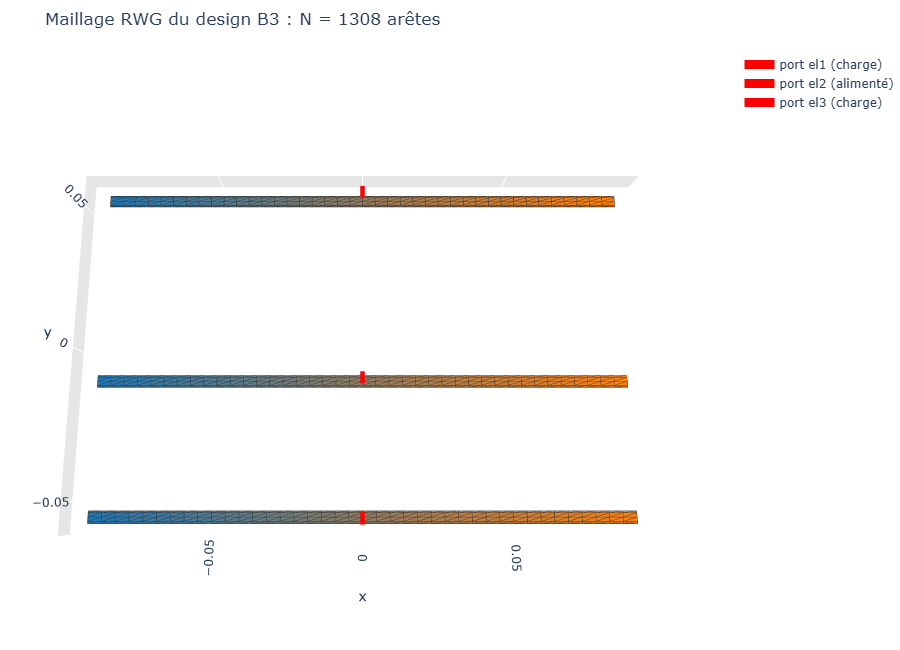

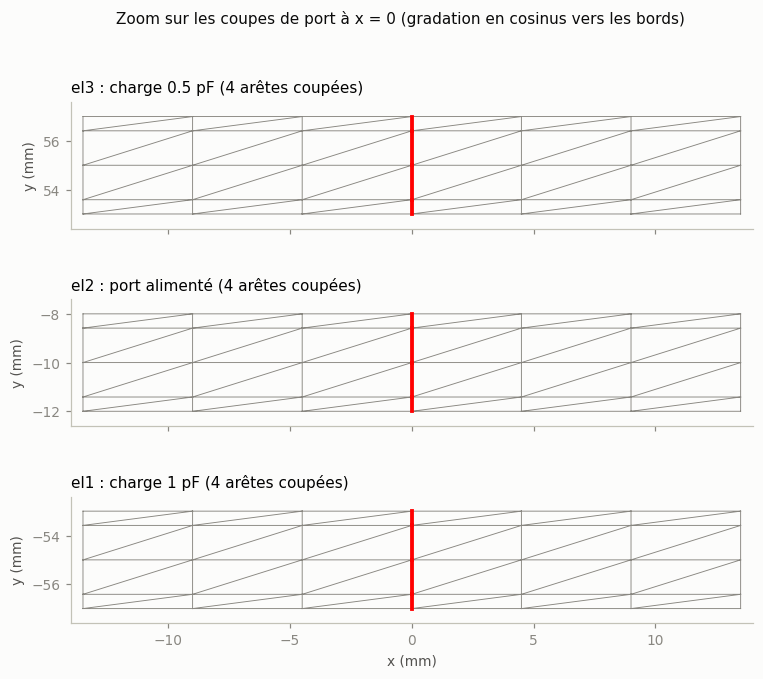

In [5]:
from solver.viewer import create_figure

pts, tri = mesh.points.points, mesh.triangles.triangles[:3].astype(int)
fig = create_figure(pts, tri + 1, title=f'Maillage RWG du design B3 : N = {mesh.n_edges} arêtes')
e1, e2 = np.asarray(mesh.edges.first_points, int), np.asarray(mesh.edges.second_points, int)
PORT_EDGES = {n: mesh.port(n).edge_indices for n in ctx.port_names}
for n, idx in PORT_EDGES.items():
    xs, ys, zs = [], [], []
    for e in idx:
        for a in (e1[e], e2[e]):
            xs.append(pts[0, a]); ys.append(pts[1, a]); zs.append(pts[2, a] + 1e-4)
        xs.append(None); ys.append(None); zs.append(None)
    fig.add_trace(go.Scatter3d(x=xs, y=ys, z=zs, mode='lines', line=dict(color='red', width=9),
                               name=f'port {n}' + (' (alimenté)' if n == fed_name else ' (charge)')))
fig.update_layout(scene=dict(aspectratio=dict(x=1, y=float(np.ptp(pts[1]) / np.ptp(pts[0])), z=0.05),
                             camera=dict(eye=dict(x=0.0, y=-0.25, z=1.25)), zaxis=dict(visible=False)),
                  margin=dict(l=0, r=0, t=50, b=0))
save_plotly(fig, '03_maillage_rwg_3d.png')

fig, axes = plt.subplots(3, 1, figsize=(8, 6.6), sharex=True)
for ax, n in zip(axes, ctx.port_names[::-1]):                       # el3 (+y) on top
    y0 = by_name[n]['y_center_mm']['value'] * 1e-3
    keep = np.all((np.abs(pts[0, tri]) < 0.016) & (np.abs(pts[1, tri] - y0) < 0.004), axis=0)
    ax.triplot(pts[0] * 1e3, pts[1] * 1e3, tri[:, keep].T, color=MUTED, lw=0.6)
    for e in PORT_EDGES[n]:
        ax.plot(pts[0, [e1[e], e2[e]]] * 1e3, pts[1, [e1[e], e2[e]]] * 1e3, color='red', lw=2.5)
    c = by_name[n]['component']
    ax.set_title(f"{n} : {'port alimenté' if n == fed_name else 'charge ' + c['label']} "
                 f'({len(PORT_EDGES[n])} arêtes coupées)', loc='left')
    ax.set_xlim(-14, 14); ax.set_ylim(y0 * 1e3 - 2.6, y0 * 1e3 + 2.6); ax.set_aspect('equal')
    ax.set_ylabel('y (mm)'); ax.grid(False)
axes[-1].set_xlabel('x (mm)')
fig.suptitle('Zoom sur les coupes de port à x = 0 (gradation en cosinus vers les bords)', fontsize=10, color=INK)
save(fig, '03_maillage_zoom_ports.png')

## 4. Courants de surface à 1 GHz

|J| par triangle, calculé et tracé avec `rwg5.calculate_current_density` et `rwg5.visualize_surface_current`.
Excitation : force électromotrice de 1 V derrière 50 Ω sur el2, capacités du kit sur el1 et el3.
Le second graphique donne le courant total i(x) de chaque ruban (intégré sur la largeur) : sens instantané
(flèches, à la phase de référence du générateur), module, et phase par rapport au courant du port alimenté.
Les flèches 3D de `visualize_surface_current` sont illisibles sur des rubans de 4 mm : le sens est donc montré en 2D.

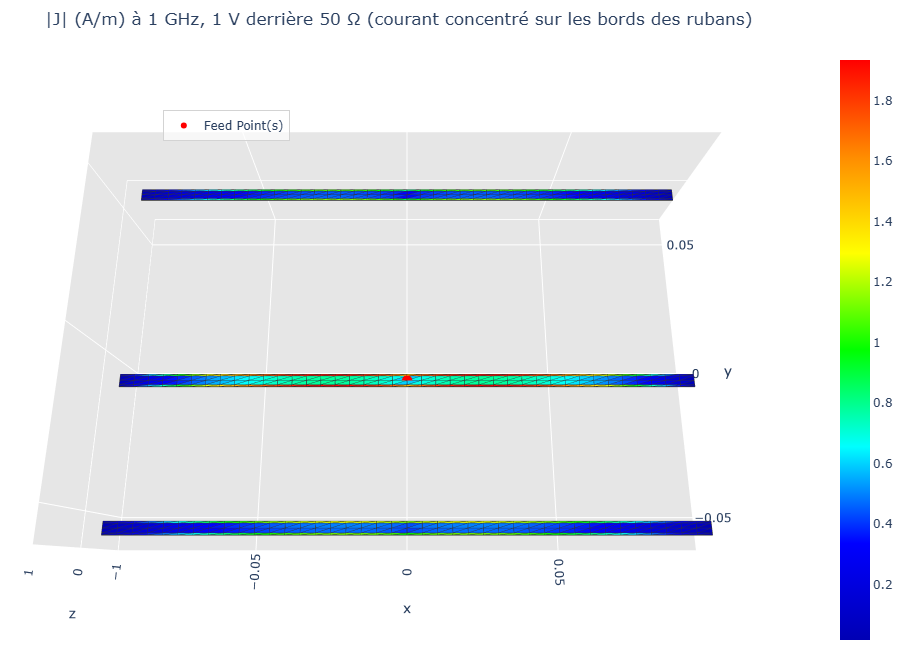

In [6]:
from solver.rwg.rwg5 import calculate_current_density, visualize_surface_current

J_ABS, J_VEC = calculate_current_density(I_EDGE, mesh.triangles, mesh.edges, mesh.vecteurs_rho)
fig = visualize_surface_current(mesh.points, mesh.triangles, J_ABS,
                                feed_point=[[0.0, by_name[fed_name]['y_center_mm']['value'] * 1e-3, 0.0]],
                                title='|J| (A/m) à 1 GHz, 1 V derrière 50 Ω (courant concentré sur les bords des rubans)')
fig.update_layout(scene=dict(camera=dict(eye=dict(x=0.0, y=-0.35, z=1.15))), margin=dict(l=0, r=0, t=50, b=0))
save_plotly(fig, '04_courants_surface_3d.png')

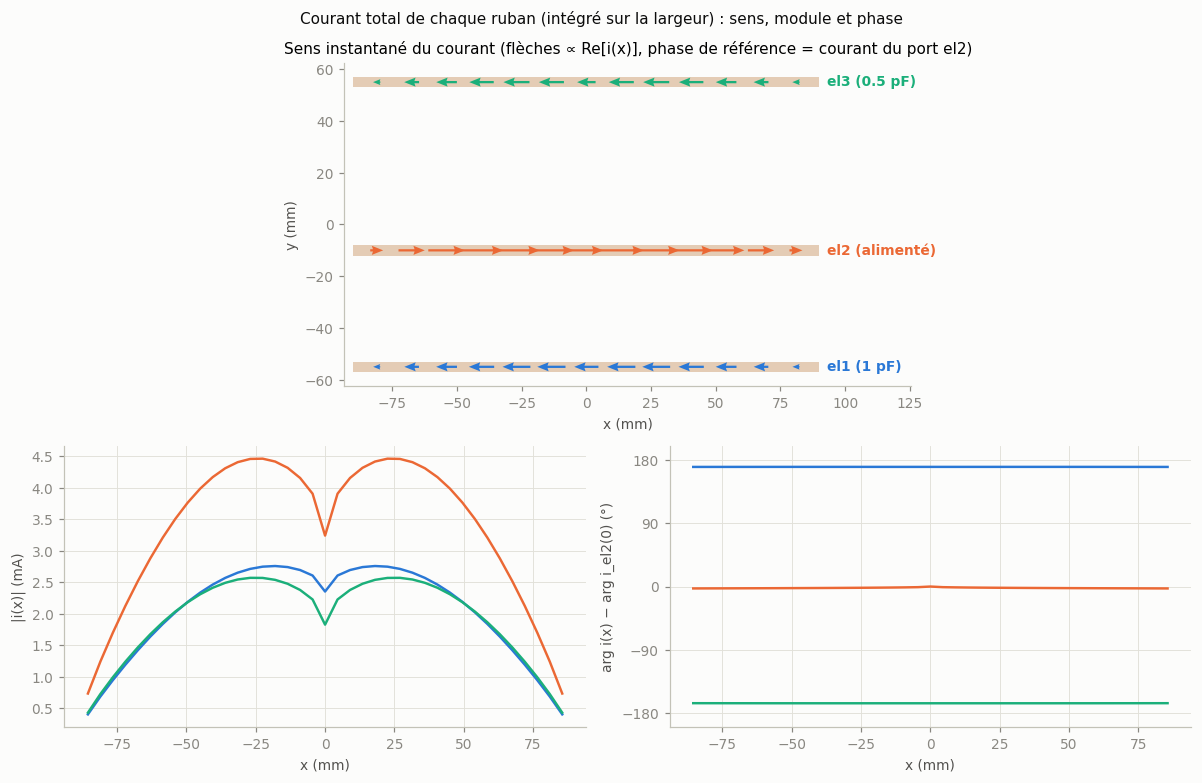

| ruban | |i(0)| (mA) | |i / i_el2| | phase / el2 (°) |
|---|---|---|---|
| el1 | 2.35 | 0.726 | +170.1 |
| el2 | 3.24 | 1.000 | -0.0 |
| el3 | 1.83 | 0.564 | -166.0 |

**À retenir :** au centre, les courants des parasites valent 0,73 (el1) et 0,56 (el3) fois celui de l'élément alimenté et sont presque en opposition de phase avec lui ; la phase décroît de −y vers +y (el1 +170°, el2 0°, el3 -166°). Le déphasage entre rubans voisins (170° et 166°) est bien plus grand que le retard de propagation k·d (54° et 78°) : c'est la signature d'un réseau end-fire superdirectif, dont les champs se compensent en grande partie, sauf autour de +y. Le creux de |i| à x = 0 est le saut de pente imposé par le générateur et par les capacités localisées ; les rubans mesurent 0,60 λ, donc le maximum de courant n'est pas au centre.

In [7]:
from solver.optim.ports import port_from_cut

xs_grid = np.asarray(mesh.xs)
I_X = {}
for s in strips:
    y0, half = s['y_center_mm']['value'] * 1e-3, s['width_mm'] * 1e-3 / 2
    xin = xs_grid[np.abs(xs_grid) < s['length_mm'] * 1e-3 / 2 - 1e-9]
    cur = []
    for x in xin:
        p = port_from_cut(mesh.points, mesh.triangles, mesh.edges, [x, y0 - half, 0], [x, y0 + half, 0],
                          [1, 0, 0], f"{s['name']}_x{x * 1e3:.1f}")
        cur.append(p.incidence_vector(mesh.edges) @ I_EDGE)
    I_X[s['name']] = (xin, np.array(cur))

i_ref = I_X[fed_name][1][np.argmin(np.abs(I_X[fed_name][0]))]
i_scale = max(np.max(np.abs(i)) for _, i in I_X.values())
fig = plt.figure(figsize=(11, 7.2))
gs = fig.add_gridspec(2, 2, height_ratios=[1.15, 1])
ax0 = fig.add_subplot(gs[0, :])
for k, s in enumerate(strips):
    x, i = I_X[s['name']]
    (x0, x1), (y0, y1) = s['x_extent_mm']['value'], s['y_edges_mm']['value']
    ax0.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, color=COPPER, alpha=0.35, lw=0))
    sel = slice(1, None, 3)
    u = np.real(i[sel] * np.exp(-1j * np.angle(i_ref))) / i_scale        # instantaneous current at the reference phase
    ax0.quiver(x[sel] * 1e3 - 9 * u, np.full(u.shape, s['y_center_mm']['value']), 18 * u, np.zeros_like(u),
               angles='xy', scale_units='xy', scale=1, color=SERIES[k], width=0.004, headwidth=4)
    lab = s['name'] + (' (alimenté)' if s['name'] == fed_name else f" ({s['component']['label']})")
    ax0.text(x1 + 3, s['y_center_mm']['value'], lab, va='center', color=SERIES[k], fontweight='bold')
ax0.set_xlim(-W_BOX / 2, W_BOX / 2 + 32); ax0.set_ylim(-L_BOX / 2, L_BOX / 2)
ax0.set_aspect('equal'); ax0.set_xlabel('x (mm)'); ax0.set_ylabel('y (mm)'); ax0.grid(False)
ax0.set_title('Sens instantané du courant (flèches ∝ Re[i(x)], phase de référence = courant du port el2)')
axes = [fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])]
for k, s in enumerate(strips):
    x, i = I_X[s['name']]
    axes[0].plot(x * 1e3, np.abs(i) * 1e3, color=SERIES[k])
    axes[1].plot(x * 1e3, np.degrees(np.angle(i / i_ref)), color=SERIES[k])
axes[0].set_ylabel('|i(x)| (mA)'); axes[1].set_ylabel('arg i(x) − arg i_el2(0) (°)')
axes[1].set_ylim(-200, 200); axes[1].set_yticks(range(-180, 181, 90))
for ax in axes:
    ax.set_xlabel('x (mm)')
fig.suptitle('Courant total de chaque ruban (intégré sur la largeur) : sens, module et phase', fontsize=10, color=INK)
fig.tight_layout()
save(fig, '04_courant_le_long_des_rubans.png')

rows, phase, ratio = [], {}, {}
for s in strips:
    x, i = I_X[s['name']]
    i0 = i[np.argmin(np.abs(x))]
    phase[s['name']] = np.degrees(np.angle(i0 / i_ref))
    ratio[s['name']] = abs(i0 / i_ref)
    rows.append([s['name'], f'{abs(i0) * 1e3:.2f}', f'{abs(i0 / i_ref):.3f}', f"{phase[s['name']]:+.1f}"])
md_table(['ruban', '|i(0)| (mA)', '|i / i_el2|', 'phase / el2 (°)'], rows)
lam_mm = OP.light_speed_c / F0 * 1e3
kd = [360 * d / lam_mm for d in PARAMS['spacings_mm']['value']]
dphi = [phase['el2'] - phase['el1'], phase['el3'] - phase['el2']]
display(Markdown(
    f"**À retenir :** au centre, les courants des parasites valent {fr(ratio['el1'])} (el1) et {fr(ratio['el3'])} (el3) "
    f"fois celui de l'élément alimenté et sont "
    f"presque en opposition de phase avec lui ; la phase décroît de −y vers +y "
    f"(el1 {phase['el1']:+.0f}°, el2 0°, el3 {phase['el3']:+.0f}°). Le déphasage entre rubans voisins "
    f"({abs(dphi[0]):.0f}° et {abs(dphi[1]):.0f}°) est bien plus grand que le retard de propagation k·d "
    f"({kd[0]:.0f}° et {kd[1]:.0f}°) : c'est la signature d'un réseau end-fire superdirectif, dont les champs se "
    f"compensent en grande partie, sauf autour de +y. Le creux de |i| à x = 0 est le saut de pente imposé par le "
    f"générateur et par les capacités localisées ; les rubans mesurent {fr(L_mm / lam_mm, 2)} λ, donc le maximum "
    f"de courant n'est pas au centre."))

## 5. Diagramme de rayonnement

Gain (adaptation idéale, pertes cuivre incluses, G = 4πU/P_in) calculé par l'intégrale exacte du champ lointain
sur les courants RWG (`solver.optim.farfield`), et non par l'approximation dipolaire.
Le 3D reprend la présentation de `efield2` (sphère déformée, dynamique de 20 dB) ; les coupes polaires reprennent
celle de `efield3`. Les points des coupes CSV de la campagne sont superposés pour contrôle.

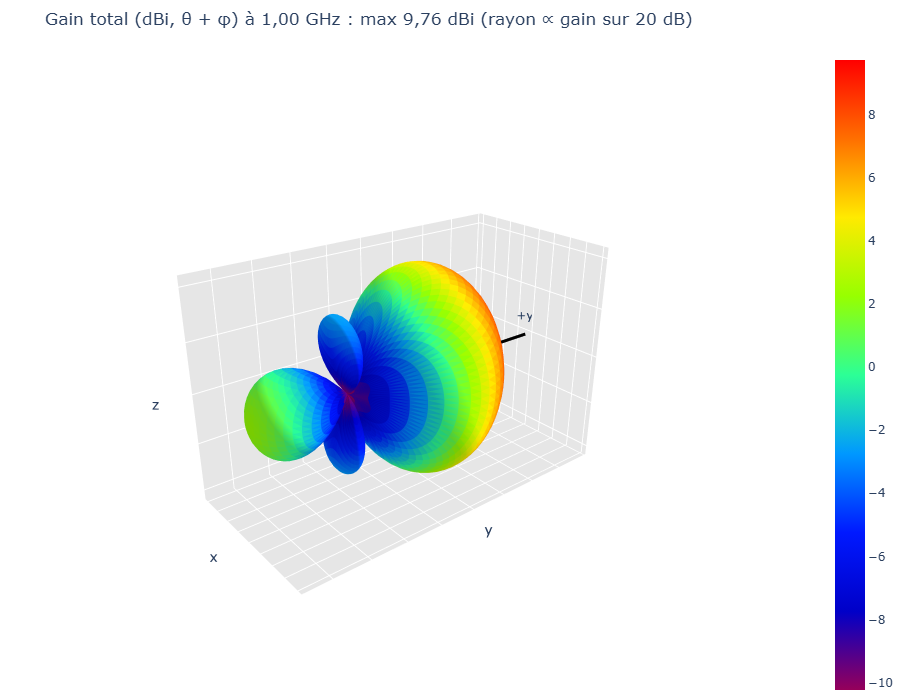

In [8]:
from solver.efield.efield2 import deform_sphere_for_radiation_pattern
from solver.efield.efield2 import visualize_surface_current as visualize_trisurf

th = np.radians(np.arange(0, 181, 3.0)); ph = np.radians(np.arange(0, 360, 3.0))
TH, PH = np.meshgrid(th, ph, indexing='ij')
ut, up = OP.intensity(I_EDGE, TH.ravel(), PH.ravel())
g_tot_db = db(np.maximum(4 * np.pi * (ut + up) / P_IN, 1e-12))
sphere = 100 * np.vstack([np.sin(TH).ravel() * np.cos(PH).ravel(), np.sin(TH).ravel() * np.sin(PH).ravel(),
                          np.cos(TH).ravel()])
nt, nph = len(th), len(ph)
idx = lambda i, j: i * nph + (j % nph)
faces = np.array([[idx(i, j), idx(i + 1, j), idx(i + 1, j + 1)] for i in range(nt - 1) for j in range(nph)]
                 + [[idx(i, j), idx(i + 1, j + 1), idx(i, j + 1)] for i in range(nt - 1) for j in range(nph)]).T
pts_def = deform_sphere_for_radiation_pattern(sphere, g_tot_db, dynamic_range=20)
fig = visualize_trisurf(pts_def, faces, np.maximum(np.mean(g_tot_db[faces], axis=0), g_tot_db.max() - 20))
r_max = float(np.max(np.linalg.norm(pts_def, axis=0)))
fig.add_trace(go.Scatter3d(x=[0, 0], y=[1.05 * r_max, 1.45 * r_max], z=[0, 0], mode='lines+text',
                           line=dict(color='black', width=6), text=['', '+y'], textposition='top center',
                           showlegend=False))
noticks = dict(showticklabels=False)
fig.update_layout(title=f'Gain total (dBi, θ + φ) à {fr(F0 / 1e9)} GHz : max {fr(g_tot_db.max())} dBi '
                        f'(rayon ∝ gain sur 20 dB)',
                  scene=dict(camera=dict(eye=dict(x=1.5, y=-1.2, z=0.9)), xaxis=noticks, yaxis=noticks, zaxis=noticks),
                  margin=dict(l=0, r=0, t=50, b=0))
save_plotly(fig, '05_diagramme_3d_gain.png', height=700)

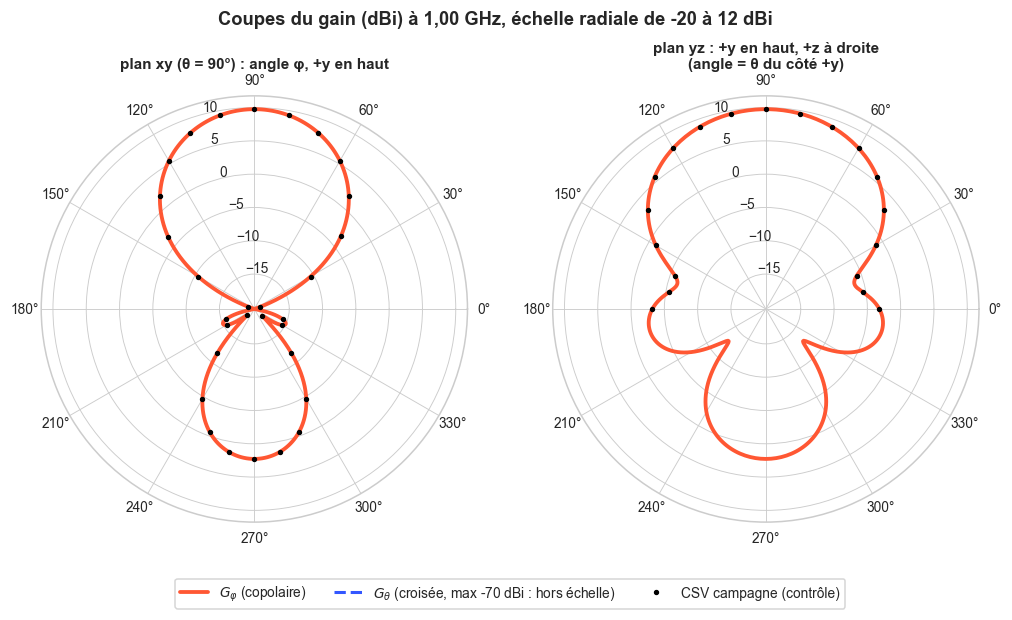

| direction | G_φ (dBi) | G_θ (dBi) | G_φ CSV (dBi) |
|---|---|---|---|
| +y (θ = 90°, φ = 90°) | 9.76 | -120.0 | 9.76 |
| −y (θ = 90°, φ = 270°) | 2.28 | -120.0 | 2.28 |
| **rapport avant/arrière** | **7.49 dB** |  | 7.49 dB (JSON : 7.49) |

Le maximum du gain total (9.76 dBi) est bien dans la direction +y à la résolution de la grille 3D ; la polarisation croisée G_θ est négligeable en +y.

In [9]:
def cut_gain(theta, phi):
    ut, up = OP.intensity(I_EDGE, theta, phi)
    return db(np.maximum(4 * np.pi * up / P_IN, 1e-12)), db(np.maximum(4 * np.pi * ut / P_IN, 1e-12))


a = np.radians(np.arange(0, 360.5, 1.0))
gxy_phi, gxy_th = cut_gain(np.full_like(a, np.pi / 2), a)                          # xy plane: angle = phi
# yz plane: angle chi with direction (0, sin chi, cos chi): theta = |chi|, phi = 90 deg (chi < 180) or 270 deg
chi = a
th_yz = np.where(chi <= np.pi, chi, 2 * np.pi - chi)
ph_yz = np.where(chi <= np.pi, np.pi / 2, 3 * np.pi / 2)
gyz_phi, gyz_th = cut_gain(th_yz, ph_yz)

csv_xy = np.array([[r['phi_deg'], r['G_phi_dBi']] for r in CUT_XY])
csv_yz = np.array([[r['theta_deg'], r['G_phi_dBi']] for r in CUT_YZ])
g_xy_csv = cut_gain(np.full(len(csv_xy), np.pi / 2), np.radians(csv_xy[:, 0]))[0]
g_yz_csv = cut_gain(np.radians(csv_yz[:, 0]), np.full(len(csv_yz), np.pi / 2))[0]
gmax = gxy_phi.max()
for name, mine, ref in (('coupe xy (θ = 90°)', g_xy_csv, csv_xy[:, 1]), ('coupe yz (φ = 90°)', g_yz_csv, csv_yz[:, 1])):
    m = ref > gmax - 30
    check(f'G_φ recalculé vs CSV, {name}, à 30 dB du max', mine[m], ref[m], 1e-3, 'dB')

with plt.style.context('seaborn-v0_8-whitegrid'):
    fig, axes = plt.subplots(1, 2, figsize=(11, 5.6), subplot_kw={'projection': 'polar'})
    for ax, (ang, gp, gt, title) in zip(axes, (
            (a, gxy_phi, gxy_th, 'plan xy (θ = 90°) : angle φ, +y en haut'),
            (chi, gyz_phi, gyz_th, 'plan yz : +y en haut, +z à droite\n(angle = θ du côté +y)'))):
        ax.set_theta_offset(0); ax.set_theta_direction(1)
        ax.plot(ang, np.maximum(gp, gmax - 30), color='#FF5733', lw=2.5, label=r'$G_\varphi$ (copolaire)')
        ax.plot(ang, np.maximum(gt, gmax - 30), color='#3357FF', lw=2.0, ls='--',
                label=rf'$G_\theta$ (croisée, max {max(gxy_th.max(), gyz_th.max()):.0f} dBi : hors échelle)')
        ax.set_thetagrids(np.arange(0, 360, 30))
        ax.set_rlim(gmax - 30, gmax + 2); ax.set_rticks(np.arange(np.ceil((gmax - 25) / 5) * 5, gmax + 1, 5))
        ax.set_rlabel_position(105)
        ax.set_title(title, pad=18, fontweight='bold')
    axes[0].plot(np.radians(csv_xy[::10, 0]), csv_xy[::10, 1], 'k.', ms=5, label='CSV campagne (contrôle)')
    axes[1].plot(np.radians(csv_yz[::10, 0]), csv_yz[::10, 1], 'k.', ms=5)
    axes[0].legend(loc='lower center', bbox_to_anchor=(1.1, -0.22), ncol=3, frameon=True)
    fig.suptitle(f'Coupes du gain (dBi) à {fr(F0 / 1e9)} GHz, échelle radiale de {gmax - 30:.0f} à {gmax + 2:.0f} dBi',
                 fontsize=12, fontweight='bold')
    save(fig, '05_coupes_polaires_xy_yz.png')

g_fwd = cut_gain(np.array([DIRECTION[0]]), np.array([DIRECTION[1]]))
g_bwd = cut_gain(np.array([BACK[0]]), np.array([BACK[1]]))
fb = g_fwd[0][0] - g_bwd[0][0]
csv_fwd = next(r['G_phi_dBi'] for r in CUT_XY if r['phi_deg'] == 90)
csv_bwd = next(r['G_phi_dBi'] for r in CUT_XY if r['phi_deg'] == 270)
md_table(['direction', 'G_φ (dBi)', 'G_θ (dBi)', 'G_φ CSV (dBi)'], [
    ['+y (θ = 90°, φ = 90°)', f'{g_fwd[0][0]:.2f}', f'{g_fwd[1][0]:.1f}', f'{csv_fwd:.2f}'],
    ['−y (θ = 90°, φ = 270°)', f'{g_bwd[0][0]:.2f}', f'{g_bwd[1][0]:.1f}', f'{csv_bwd:.2f}'],
    ['**rapport avant/arrière**', f'**{fb:.2f} dB**', '', f"{csv_fwd - csv_bwd:.2f} dB (JSON : {PARAMS['expected']['FB_dB']:.2f})"]])
check('F/B recalculé vs JSON', fb, PARAMS['expected']['FB_dB'], 1e-3, 'dB')
check('F/B : CSV coupe xy vs CSV fréquence (f₀)', csv_fwd - csv_bwd, row0['FB_dB'], 1e-3, 'dB')
check('G_φ(+y) recalculé vs G du JSON', g_fwd[0][0], PARAMS['expected']['G_kit_dBi'], 1e-3, 'dB')
display(Markdown(f"Le maximum du gain total ({g_tot_db.max():.2f} dBi) est bien dans la direction +y à la "
                 f"résolution de la grille 3D ; la polarisation croisée G_θ est négligeable en +y."))

## 6. Performances en fréquence

Composants figés, Z recalculé à chaque fréquence (campagne B3, 9 points de f₀ − 2 % à f₀ + 2 %, fichier
`V6_expected_B3_1.00GHz_freq.csv`). Le gain avec adaptation idéale varie peu, mais Z_in est très réactif (Q_in ≈ 62) :
sans réseau, le gain réalisé sur 50 Ω est négatif. Le réseau d'adaptation n° 1 de l'étape 6b (2,7 pF en parallèle,
puis 1,2 + 1,2 pF en série) récupère presque tout le gain, sur une bande d'environ 1 %.

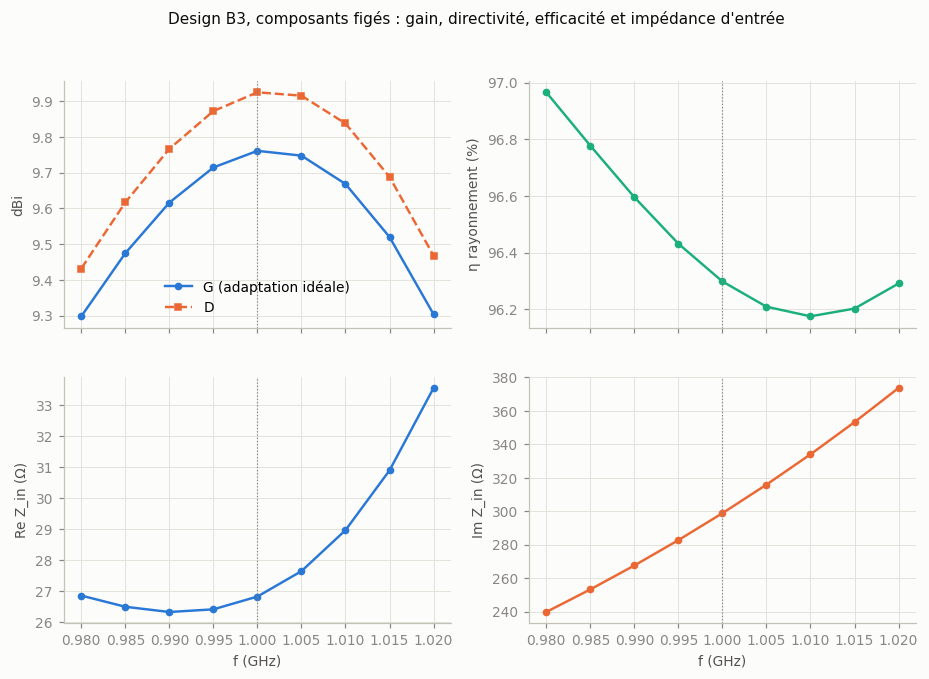

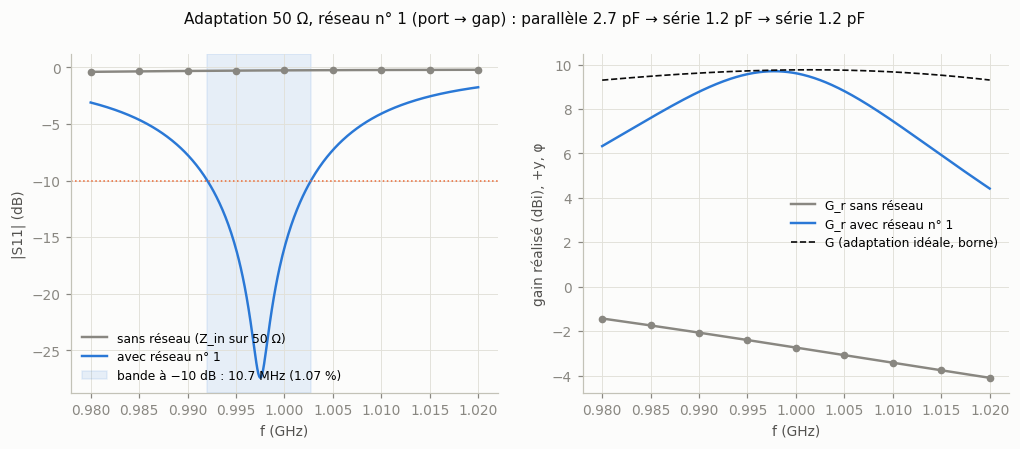

|  | sans réseau | avec réseau n° 1 |
|---|---|---|
| |S11| à f₀ (dB) | -0.25 | -15.9 |
| G_r nominal à f₀ (dBi) | -2.73 | 9.61 |
| G_r moyen / P10 (tolérances × f₀ ± 0,5 %) | — | 9.34 / 8.71 |
| perte dans le réseau (dB) | — | 0.041 (ESR 0.1 Ω) |
| bande à −10 dB | — | 10.7 MHz (1.07 %) |

Avec les valeurs discrètes du kit, le minimum de |S11| tombe à 0,9975 GHz ; f₀ n'est qu'à 2,7 MHz du bord haut de la bande à −10 dB (bord bas à 8,0 MHz). Le réseau a été classé sur le gain réalisé moyen dans f₀ ± 0,5 %, pas sur |S11| à f₀.

In [10]:
from solver.optim.matching import AntennaOnePort

f_ghz = np.array([r['f_GHz'] for r in FREQ])
fig, axes = plt.subplots(2, 2, figsize=(10, 6.4), sharex=True)
axes[0, 0].plot(f_ghz, [r['G_dBi'] for r in FREQ], 'o-', ms=4, color=SERIES[0], label='G (adaptation idéale)')
axes[0, 0].plot(f_ghz, [r['D_dBi'] for r in FREQ], 's--', ms=4, color=SERIES[1], label='D')
axes[0, 0].set_ylabel('dBi'); axes[0, 0].legend()
axes[0, 1].plot(f_ghz, [100 * r['eta'] for r in FREQ], 'o-', ms=4, color=SERIES[2])
axes[0, 1].set_ylabel('η rayonnement (%)')
axes[1, 0].plot(f_ghz, [r['Zin_re_ohm'] for r in FREQ], 'o-', ms=4, color=SERIES[0])
axes[1, 0].set_ylabel('Re Z_in (Ω)')
axes[1, 1].plot(f_ghz, [r['Zin_im_ohm'] for r in FREQ], 'o-', ms=4, color=SERIES[1])
axes[1, 1].set_ylabel('Im Z_in (Ω)')
for ax in axes[1]:
    ax.set_xlabel('f (GHz)')
for ax in axes.ravel():
    ax.axvline(F0 / 1e9, color=MUTED, lw=0.8, ls=':')
fig.suptitle('Design B3, composants figés : gain, directivité, efficacité et impédance d\'entrée', fontsize=10, color=INK)
save(fig, '06_G_D_eta_Zin_vs_f.png')

ANT = AntennaOnePort.from_freq_rows(FREQ, F0)
sol1 = next(s for s in ADAPT['solutions'] if s['rank'] == ADAPT['recommended_rank'])
cur1 = next(c for c in ADAPT['expected_curves_top3_distinct'] if c['rank'] == sol1['rank'])
fc = np.array(cur1['f_GHz'])
z_nom = ANT.zin(fc * 1e9)
s11_nonet = 20 * np.log10(np.abs((z_nom - 50) / (z_nom + 50)))
gr_nonet = db(ANT.gain(fc * 1e9) * (1 - np.abs((z_nom - 50) / (z_nom + 50)) ** 2))
s11_csv = 20 * np.log10(np.abs([(complex(r['Zin_re_ohm'], r['Zin_im_ohm']) - 50) / (complex(r['Zin_re_ohm'], r['Zin_im_ohm']) + 50) for r in FREQ]))
band = sol1['expected']['band']
POS_FR = {'shunt': 'parallèle', 'series': 'série'}
desc1 = ' → '.join(f"{POS_FR[e['position']]} {e['label']}" for e in sol1['elements_port_to_gap'])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.0))
axes[0].plot(fc, s11_nonet, color=MUTED, label='sans réseau (Z_in sur 50 Ω)')
axes[0].plot(f_ghz, s11_csv, 'o', ms=4, color=MUTED)
axes[0].plot(fc, cur1['S11_dB'], color=SERIES[0], label=f'avec réseau n° {sol1["rank"]}')
axes[0].axhline(-10, color=SERIES[1], ls=':', lw=1)
axes[0].axvspan(band['f_lo_GHz'], band['f_hi_GHz'], color=SERIES[0], alpha=0.10,
                label=f"bande à −10 dB : {band['bw_MHz']:.1f} MHz ({band['bw_pct']:.2f} %)")
axes[0].set_ylabel('|S11| (dB)')
axes[1].plot(fc, gr_nonet, color=MUTED, label='G_r sans réseau')
axes[1].plot(f_ghz, [r['G_r_dBi'] for r in FREQ], 'o', ms=4, color=MUTED)
axes[1].plot(fc, cur1['G_r_dBi'], color=SERIES[0], label=f'G_r avec réseau n° {sol1["rank"]}')
axes[1].plot(fc, db(ANT.gain(fc * 1e9)), color=INK, ls='--', lw=1.1, label='G (adaptation idéale, borne)')
axes[1].set_ylabel('gain réalisé (dBi), +y, φ')
for ax in axes:
    ax.set_xlabel('f (GHz)'); ax.legend(fontsize=8)
fig.suptitle(f'Adaptation 50 Ω, réseau n° {sol1["rank"]} (port → gap) : {desc1}', fontsize=10, color=INK)
save(fig, '06_S11_Gr_avec_sans_reseau.png')

e1x = sol1['expected']
md_table(['', 'sans réseau', f'avec réseau n° {sol1["rank"]}'], [
    ['|S11| à f₀ (dB)', f'{s11_csv[np.argmin(np.abs(f_ghz - F0 / 1e9))]:.2f}', f"{e1x['S11_dB']:.1f}"],
    ['G_r nominal à f₀ (dBi)', f"{PARAMS['expected']['G_r_50ohm_dBi']:.2f}", f"{e1x['G_r_nominal_dBi']:.2f}"],
    ['G_r moyen / P10 (tolérances × f₀ ± 0,5 %)', '—', f"{e1x['G_r_mean_dBi']:.2f} / {e1x['G_r_p10_dBi']:.2f}"],
    ['perte dans le réseau (dB)', '—', f"{e1x['network_loss_dB']:.3f} (ESR {ADAPT['models']['capacitor']['esr_ohm_ranking']:g} Ω)"],
    ['bande à −10 dB', '—', f"{band['bw_MHz']:.1f} MHz ({band['bw_pct']:.2f} %)"]])
f_s11min = fc[int(np.argmin(cur1['S11_dB']))]
display(Markdown(
    f"Avec les valeurs discrètes du kit, le minimum de |S11| tombe à {fr(f_s11min, 4)} GHz ; f₀ n'est qu'à "
    f"{fr((band['f_hi_GHz'] - F0 / 1e9) * 1e3, 1)} MHz du bord haut de la bande à −10 dB "
    f"(bord bas à {fr((F0 / 1e9 - band['f_lo_GHz']) * 1e3, 1)} MHz). Le réseau a été classé sur le gain réalisé moyen "
    f"dans f₀ ± 0,5 %, pas sur |S11| à f₀."))

# coherence: design data of the adaptation file vs the parameters file; curve recomputed vs stored
check('adaptation : Z_A(f₀) vs paramètres', complex(*ADAPT['design']['Z_A_f0_ohm']), complex(*PARAMS['expected']['Zin_ohm']), 1e-4, 'Ω')
check('adaptation : G_A(f₀) vs paramètres', ADAPT['design']['G_A_f0_dBi'], PARAMS['expected']['G_kit_dBi'], 1e-4, 'dB')
check('adaptation : Q_in vs paramètres', ADAPT['design']['Q_in'], PARAMS['expected']['Q_in'], 1e-9)
check('adaptation : G_r sans réseau vs paramètres', ADAPT['design']['G_r_without_network_dBi'], PARAMS['expected']['G_r_50ohm_dBi'], 1e-4, 'dB')
check('G_r(50 Ω) CSV (f₀) vs paramètres', row0['G_r_dBi'], PARAMS['expected']['G_r_50ohm_dBi'], 1e-4, 'dB')
q_b3 = next(c['Q_in'] for c in CAMP_CHECKS['B3'] if c['rank'] == 1 and abs(c['f0_GHz'] - F0 / 1e9) < 1e-9)
_ = check('Q_in : B3_checks.json vs paramètres', q_b3, PARAMS['expected']['Q_in'], 1e-9)

## 7. Pourquoi 3 éléments à 1 GHz

Meilleur design robuste pour 2, 3 et 4 éléments, à 0,9 et 1,0 GHz (2 éléments : balayage A, charges continues ;
3 éléments : grille B3 ; 4 éléments : optimisation bayésienne B4, faite à 1,0 GHz seulement). G_N est le gain
« normal » de Harrington, (ka)² + 2ka, pour la sphère qui contient la boîte. Le passage de 2 à 3 éléments apporte
plus de 2 dB ; le quatrième élément n'apporte presque rien et ajoute un composant.

| K | f₀ (GHz) | écarts (mm) | G (dBi) | G robuste (dBi) | G_max (dBi) | G_N (dBi) | G − G_N (dB) | composants |
|---|---|---|---|---|---|---|---|---|
| 2 | 0.90 | 25 | 7.37 | — | — | 9.42 | -2.05 | 1.559 pF (continu) |
| 3 | 0.90 | 45/65 | 9.45 | 9.40 | 11.00 | 9.42 | +0.03 | el1 2.7 pF, el3 1.2 pF |
| 2 | 1.00 | 25 | 7.52 | — | — | 10.12 | -2.60 | 0.6712 pF (continu) |
| 3 | 1.00 | 45/65 | 9.76 | 9.47 | 11.24 | 10.12 | -0.36 | el1 1 pF, el3 0.5 pF |
| 4 | 1.00 | 26.3/24.2/62.6 | 9.82 | 9.49 | 11.42 | 10.12 | -0.30 | el1 1 pF, el2 0.3 pF, el4 0.5 pF |

G : adaptation idéale, +y, φ, composants du kit (charges continues pour K = 2). G robuste : moyenne sur α_cal × {0,85 ; 1 ; 1,15} × tolérance {−, 0, +}. G_max : borne de la géométrie (courants optimaux, pertes incluses).

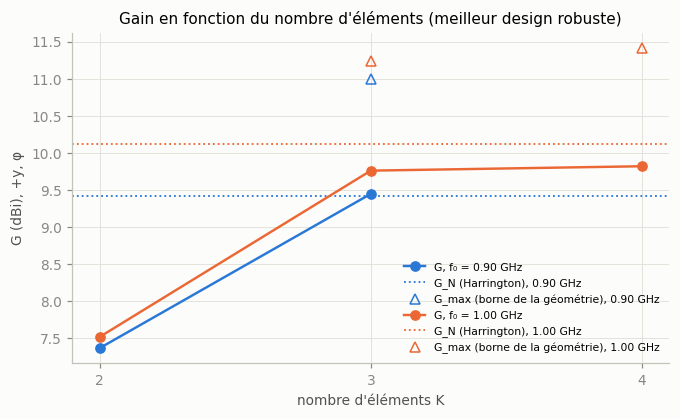

**Honnêteté :** à 1 GHz, le design à 3 éléments donne G = 9,76 dBi, soit **0,36 dB sous le gain normal de Harrington** (G_N = 10,12 dBi) : c'est un gain élevé pour la taille, pas un dépassement de Harrington. 1 GHz gagne en gain absolu, qui est le critère du règlement ; le 4ᵉ élément n'apporte que 0,06 dB.

In [11]:
C0 = 1 / np.sqrt(8.854e-12 * 1.257e-6)
BOX_A = np.hypot(W_BOX / 2, L_BOX / 2) * 1e-3          # as in exploration_3_4_elements.ipynb


def harrington_db(f_ghz):
    ka = 2 * np.pi * f_ghz * 1e9 / C0 * BOX_A
    return float(10 * np.log10(ka ** 2 + 2 * ka)), ka


def mm(sp):
    return '/'.join(f'{round(d, 1):g}' for d in sp)


CMP = []
for f in (0.9, 1.0):
    gn = harrington_db(f)[0]
    a2 = [r for r in A2 if r['alpha_factor'] == 1.0 and r['best_config'] is True and abs(r['f_GHz'] - f) < 1e-9]
    if a2:
        b = max(a2, key=lambda r: r['G'])
        CMP.append(dict(K=2, f0=f, geo=f"{b['spacing_mm']:g}", G=b['G_dBi'], G_rob=np.nan, Gmax=np.nan, GN=gn,
                        parts=f"{b['element_label']} (continu)"))
    for camp, recs in (('B3', B3), ('B4', B4)):
        best = [r for r in recs if r['best_fed'] and abs(r['f0_GHz'] - f) < 1e-9]
        if best:
            b = max(best, key=lambda r: r['objective'])
            CMP.append(dict(K=b['n_elements'], f0=f, geo=mm(b['spacings_mm']), G=b['G_kit_dBi'], G_rob=b['G_robust_mean_dBi'],
                            Gmax=b['G_max_dBi'], GN=gn, parts=', '.join(f"{ld['port']} {ld['label']}" for ld in b['loads']), rec=b))
nan = lambda v, n=2: '—' if not np.isfinite(v) else f'{v:.{n}f}'
md_table(['K', 'f₀ (GHz)', 'écarts (mm)', 'G (dBi)', 'G robuste (dBi)', 'G_max (dBi)', 'G_N (dBi)', 'G − G_N (dB)', 'composants'],
         [[r['K'], f"{r['f0']:.2f}", r['geo'], f"{r['G']:.2f}", nan(r['G_rob']), nan(r['Gmax']), f"{r['GN']:.2f}",
           f"{r['G'] - r['GN']:+.2f}", r['parts']] for r in CMP])
display(Markdown('G : adaptation idéale, +y, φ, composants du kit (charges continues pour K = 2). '
                 'G robuste : moyenne sur α_cal × {0,85 ; 1 ; 1,15} × tolérance {−, 0, +}. '
                 'G_max : borne de la géométrie (courants optimaux, pertes incluses).'))

fig, ax = plt.subplots(figsize=(7, 3.9))
for i, f in enumerate((0.9, 1.0)):
    sel = [r for r in CMP if r['f0'] == f]
    ax.plot([r['K'] for r in sel], [r['G'] for r in sel], marker='o', ms=6, color=SERIES[i], label=f'G, f₀ = {f:.2f} GHz')
    ax.axhline(harrington_db(f)[0], color=SERIES[i], ls=':', lw=1.2, label=f'G_N (Harrington), {f:.2f} GHz')
    gm = [r for r in sel if np.isfinite(r['Gmax'])]
    ax.plot([r['K'] for r in gm], [r['Gmax'] for r in gm], marker='^', ls='none', ms=6, mfc='none', color=SERIES[i],
            label=f'G_max (borne de la géométrie), {f:.2f} GHz')
ax.set_xticks([2, 3, 4]); ax.set_xlabel("nombre d'éléments K"); ax.set_ylabel('G (dBi), +y, φ')
ax.legend(fontsize=7, loc='lower right')
ax.set_title("Gain en fonction du nombre d'éléments (meilleur design robuste)")
save(fig, '07_G_vs_nombre_elements.png')

b3_1 = next(r for r in CMP if r['K'] == 3 and r['f0'] == 1.0)
b4_1 = next((r for r in CMP if r['K'] == 4 and r['f0'] == 1.0), None)
gap_gn = b3_1['GN'] - b3_1['G']
display(Markdown(
    f"**Honnêteté :** à 1 GHz, le design à 3 éléments donne G = {fr(b3_1['G'])} dBi, soit **{fr(gap_gn)} dB sous le gain "
    f"normal de Harrington** (G_N = {fr(b3_1['GN'])} dBi) : c'est un gain élevé pour la taille, pas un dépassement "
    f"de Harrington. 1 GHz gagne en gain absolu, qui est le critère du règlement"
    + (f" ; le 4ᵉ élément n'apporte que {fr(b4_1['G'] - b3_1['G'])} dB." if b4_1 else '.')))

rec = b3_1['rec']
check('B3_designs.jsonl (meilleur à 1 GHz) : écarts vs paramètres', rec['spacings_mm'], PARAMS['spacings_mm']['value'], 1e-9, 'mm')
check('B3_designs.jsonl : G_kit vs paramètres', rec['G_kit_dBi'], PARAMS['expected']['G_kit_dBi'], 1e-9, 'dB')
check('B3_designs.jsonl : G robuste moyen vs paramètres', rec['G_robust_mean_dBi'], PARAMS['expected']['G_robust_mean_dBi'], 1e-9, 'dB')
check('B3_designs.jsonl : G_max vs paramètres', rec['G_max_dBi'], PARAMS['expected']['G_max_dBi'], 1e-9, 'dB')
check('B3_designs.jsonl : élément alimenté = paramètres', float(rec['fed'] == fed_name), 1.0, 0)
for ld in rec['loads']:
    check(f"B3_designs.jsonl : charge {ld['port']} = composant des paramètres", ld['value_F'],
          by_name[ld['port']]['component']['value_F'], 1e-18, 'F')

## 8. Robustesse

Quatre sources d'écart : tolérances des capacités de charge, ESR/ESL des composants, décalage de fréquence, et
tolérances du réseau d'adaptation. Le Monte-Carlo (500 tirages uniformes dans ± la tolérance, graine fixe, × 5
fréquences de f₀ − 0,5 % à f₀ + 0,5 %) est recalculé ici à partir des données de fréquence (modèle circuit,
sans nouveau calcul MoM) et comparé aux statistiques enregistrées par l'étape 6b.

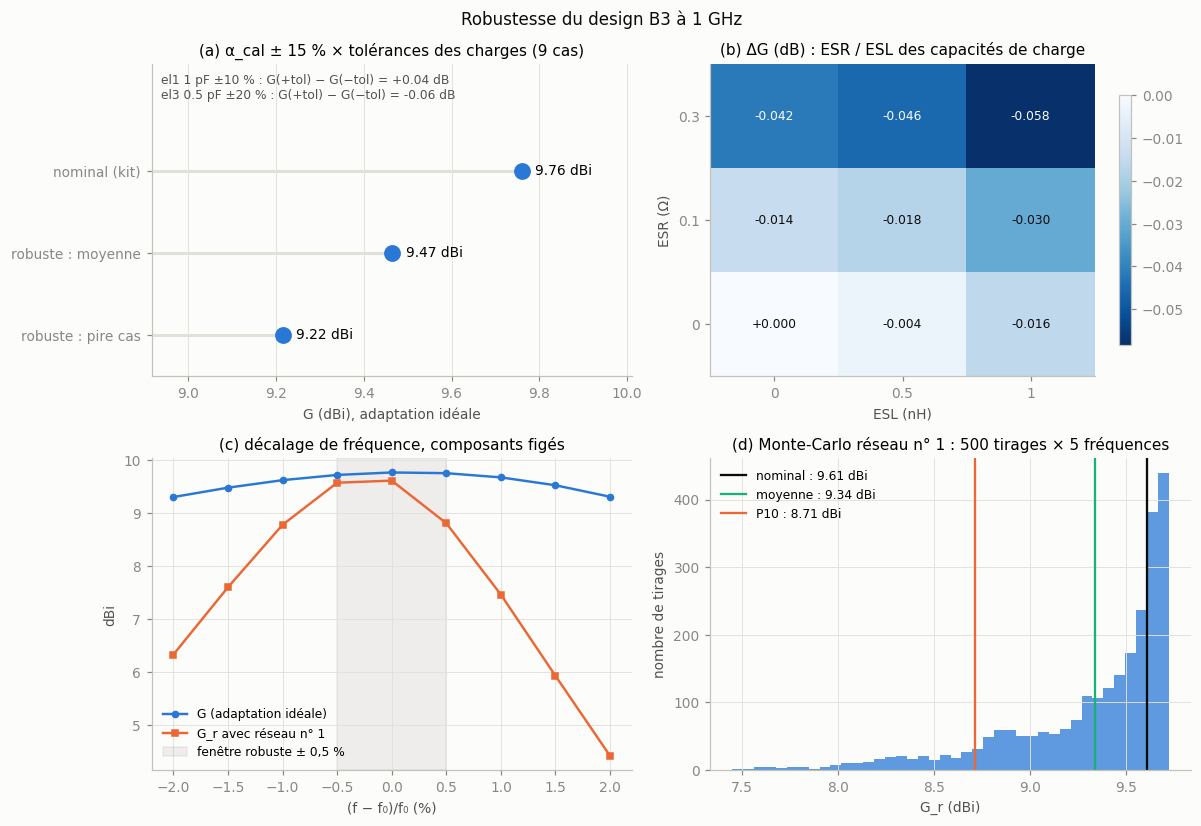

| f₀ (offset) | −2 % | −1,5 % | −1 % | −0,5 % | 0 | +0,5 % | +1 % | +1,5 % | +2 % |
|---|---|---|---|---|---|---|---|---|---|
| G adaptation idéale (dBi) | 9.30 | 9.47 | 9.62 | 9.71 | 9.76 | 9.75 | 9.67 | 9.52 | 9.30 |
| G_r réseau n° 1 (dBi) | 6.33 | 7.60 | 8.78 | 9.57 | 9.61 | 8.80 | 7.46 | 5.93 | 4.42 |

**À retenir :** les tolérances des charges et les ESR/ESL coûtent quelques centièmes à quelques dixièmes de dB (ESR 0,3 Ω + ESL 1 nH : -0,06 dB). Avec le réseau d'adaptation, la perte robuste vient surtout de la **fréquence** : tolérances seules, moyenne 9,53 dBi ; f₀ ± 0,5 % seul, moyenne 9,41 dBi. À ± 2 %, G_r tombe à 4,42 dBi : le recalage de f₀ dans CST est le point critique.

In [12]:
from solver.optim.components import ComponentModel, InductorModel
from solver.optim.matching import TOPOLOGIES, respond, tolerance_draws

pos = TOPOLOGIES[sol1['topology']]
els = sol1['elements_port_to_gap']
check('réseau n° 1 : positions du JSON = topologie', float([e['position'] for e in els] == list(pos)), 1.0, 0)
is_ind = np.array([e['type'] == 'inductor' for e in els])
nom = np.array([e['value'] for e in els]); tol = np.array([e['tolerance_abs'] for e in els])
mc = ADAPT['models']
CAP_MODEL = ComponentModel(mc['capacitor']['esr_ohm_ranking'], mc['capacitor']['esl_nH_ranking'] * 1e-9)
IND_MODEL = InductorModel(mc['inductor']['q_ranking'], mc['inductor']['c_par_pF_ranking'] * 1e-12)
u = tolerance_draws(ADAPT['robust']['n_mc'], 3, ADAPT['robust']['seed'])
offs = np.array(ADAPT['robust']['f_offsets_pct']) / 100
vals = nom[None, None, :] + u[:, None, :len(nom)] * tol[None, None, :]
G_MC = db(respond(pos, is_ind, vals, (F0 * (1 + offs))[None, :], ANT, CAP_MODEL, IND_MODEL)['G_r']).ravel()
mean_db, p10_db = float(db(np.mean(10 ** (G_MC / 10)))), float(np.percentile(G_MC, 10))
check('Monte-Carlo recalculé : G_r moyen vs JSON 6b', mean_db, sol1['expected']['G_r_mean_dBi'], 1e-6, 'dB')
check('Monte-Carlo recalculé : G_r P10 vs JSON 6b', p10_db, sol1['expected']['G_r_p10_dBi'], 1e-6, 'dB')
g_curve = db(respond(pos, is_ind, nom[None, :], fc * 1e9, ANT, CAP_MODEL, IND_MODEL)['G_r'])
check('courbe G_r(f) recalculée vs JSON 6b', g_curve, cur1['G_r_dBi'], 1e-6, 'dB')

fig, axes = plt.subplots(2, 2, figsize=(11, 7.6))
# (a) load tolerances
ax = axes[0, 0]
labels = ['nominal (kit)', 'robuste : moyenne', 'robuste : pire cas']
vals_a = [PARAMS['expected']['G_kit_dBi'], PARAMS['expected']['G_robust_mean_dBi'], PARAMS['expected']['G_robust_worst_dBi']]
ax.hlines(range(3), min(vals_a) - 0.3, vals_a, color=GRID, lw=2)
ax.plot(vals_a, range(3), 'o', ms=10, color=SERIES[0])
for k, v in enumerate(vals_a):
    ax.text(v + 0.03, k, f'{v:.2f} dBi', va='center')
ax.set_yticks(range(3), labels); ax.invert_yaxis()
ax.set_xlim(min(vals_a) - 0.3, max(vals_a) + 0.25); ax.set_xlabel('G (dBi), adaptation idéale'); ax.grid(axis='y')
ax.set_title('(a) α_cal ± 15 % × tolérances des charges (9 cas)')
txt = '\n'.join(f"{ld['port']} {ld['label']} ±{100 * ld['tol_rel']:.0f} % : G(+tol) − G(−tol) = {ld['dG_tolerance_dB']:+.2f} dB"
                for ld in rec['loads'])
ax.text(0.02, 0.97, txt, transform=ax.transAxes, fontsize=8, color=INK_2, va='top')
ax.set_ylim(2.5, -1.3)
# (b) ESR x ESL of the load capacitors
ax = axes[0, 1]
grid = PARAMS['esr_esl_sensitivity']
esr = sorted({g['esr_ohm'] for g in grid}); esl = sorted({g['esl_nH'] for g in grid})
M = np.array([[next(g['G_dBi'] for g in grid if g['esr_ohm'] == r and g['esl_nH'] == l) for l in esl] for r in esr])
im = ax.imshow(M - PARAMS['expected']['G_kit_dBi'], cmap='Blues_r', origin='lower', aspect='auto')
for i in range(len(esr)):
    for j in range(len(esl)):
        ax.text(j, i, f'{M[i, j] - M[0, 0]:+.3f}', ha='center', va='center', fontsize=8,
                color='white' if M[i, j] - M[0, 0] < -0.04 else INK)
ax.set_xticks(range(len(esl)), [f'{v:g}' for v in esl]); ax.set_yticks(range(len(esr)), [f'{v:g}' for v in esr])
ax.set_xlabel('ESL (nH)'); ax.set_ylabel('ESR (Ω)'); ax.grid(False)
ax.set_title('(b) ΔG (dB) : ESR / ESL des capacités de charge')
fig.colorbar(im, ax=ax, shrink=0.8)
# (c) frequency offset
ax = axes[1, 0]
off_pct = np.array([r['offset_pct'] for r in FREQ])
ax.plot(off_pct, [r['G_dBi'] for r in FREQ], 'o-', ms=4, color=SERIES[0], label='G (adaptation idéale)')
gr_at = np.interp(f_ghz, fc, cur1['G_r_dBi'])
ax.plot(off_pct, gr_at, 's-', ms=4, color=SERIES[1], label=f'G_r avec réseau n° {sol1["rank"]}')
ax.axvspan(-0.5, 0.5, color=MUTED, alpha=0.12, label='fenêtre robuste ± 0,5 %')
ax.set_xlabel('(f − f₀)/f₀ (%)'); ax.set_ylabel('dBi'); ax.legend(fontsize=8)
ax.set_title('(c) décalage de fréquence, composants figés')
# (d) Monte-Carlo histogram
ax = axes[1, 1]
ax.hist(G_MC, bins=40, color=SERIES[0], alpha=0.75)
for v, lab, c in ((sol1['expected']['G_r_nominal_dBi'], 'nominal', INK), (mean_db, 'moyenne', SERIES[2]), (p10_db, 'P10', SERIES[1])):
    ax.axvline(v, color=c, lw=1.5, label=f'{lab} : {v:.2f} dBi')
ax.set_xlabel('G_r (dBi)'); ax.set_ylabel('nombre de tirages')
ax.set_title(f"(d) Monte-Carlo réseau n° {sol1['rank']} : {ADAPT['robust']['n_mc']} tirages × {len(offs)} fréquences")
ax.legend(fontsize=8)
fig.suptitle('Robustesse du design B3 à 1 GHz', fontsize=11, color=INK)
fig.tight_layout()
save(fig, '08_robustesse.png')

dec = ADAPT['robust_decomposition_rank1']
md_table(['f₀ (offset)', '−2 %', '−1,5 %', '−1 %', '−0,5 %', '0', '+0,5 %', '+1 %', '+1,5 %', '+2 %'], [
    ['G adaptation idéale (dBi)'] + [f"{r['G_dBi']:.2f}" for r in FREQ],
    [f"G_r réseau n° {sol1['rank']} (dBi)"] + [f'{v:.2f}' for v in gr_at]])
display(Markdown(
    f"**À retenir :** les tolérances des charges et les ESR/ESL coûtent quelques centièmes à quelques dixièmes de dB "
    f"(ESR 0,3 Ω + ESL 1 nH : {fr(M[-1, -1] - M[0, 0])} dB). Avec le réseau d'adaptation, la perte robuste vient "
    f"surtout de la **fréquence** : tolérances seules, moyenne {fr(dec['tolerances_only_mean_dBi'])} dBi ; f₀ ± 0,5 % "
    f"seul, moyenne {fr(dec['frequency_only_mean_dBi'])} dBi. À ± 2 %, G_r tombe à {fr(gr_at.min())} dBi : "
    f"le recalage de f₀ dans CST est le point critique."))

## 9. Validation du solveur (résumé)

Trois validations contre CST, faites aux étapes 2 à 5 : le dipôle V5a (port et matrice Z), la petite boucle V5b′
(R_rad, f_res et pertes, à géométrie égale) et la correction de l'assemblage de Z (fuite de Φ et inductance
statique comparée à Grover). Les figures existantes de `resultats_V5/figures/` sont réutilisées ; le tableau est
reconstruit à partir des fichiers MoM, CST et du diagnostic JSON.

V5a : 0 cas MoM archivés dans resultats_V5/mom


| w (mm) | f_res PEC MoM / CST (GHz) | écart f_res | R_rad MoM / CST (Ω) | écart R_rad | η MoM (α_cal) / CST | α_cal |
|---|---|---|---|---|---|---|
| 1 | 0.8787 / 0.8957 | -1.90 % | 0.335 / 0.348 | -3.6 % | 0.432 / 0.431 | 0.71 |
| 2 | 0.8800 / 0.8921 | -1.35 % | 0.257 / 0.265 | -3.1 % | 0.512 / 0.511 | 0.81 |
| 4 | 0.8855 / 0.8848 | +0.08 % | 0.136 / 0.139 | -2.1 % | 0.471 / 0.475 | 1.09 |

| test | ce qu'il valide | écart |
|---|---|---|
| V5a dipôle PEC 150 × 4 mm, Z_in à 0,9 GHz | port delta-gap et matrice Z | MoM 62.73 -24.46j Ω contre CST 63.07 -18.35j Ω : Re -0.5 %, Im -6.1 Ω (port CST : edge port sur un gap de 0,5 mm) — *valeur MoM citée, balayage non archivé* |
| V5b′ petite boucle (côté extérieur 20 mm), PEC, à géométrie égale | réactance de boucle (f_res) | f_res : -1.90 à +0.08 % |
| V5b′, PEC, C retouchée à la f_res de CST | R_rad (partie réelle de Z, champ lointain) | -3.6 à -2.1 % |
| V5b′ cuivre | pertes : α_cal(w) | η à 0.005 près — *α_cal est calibré sur ces mêmes données : accord par construction, pas une validation indépendante* |
| Puissance rayonnée : intégrale sur la sphère vs ½ Iᴴ Re(Z) I | champ lointain exact (farfield.py) | écart relatif 7.4e-13 |
| Correction de l'assemblage de Z (boucle, courant solénoïdal) | neutralité du terme Φ | Φ/A : 0.107 (recopie miroir) → 5e-13 (full_sym) |
| L statique de la boucle (200 MHz) vs Grover | inductance (partie A) | miroir 83.8 nH (+80 %) → full_sym 48.8 nH (+4.6 %), Grover 46.7 nH |

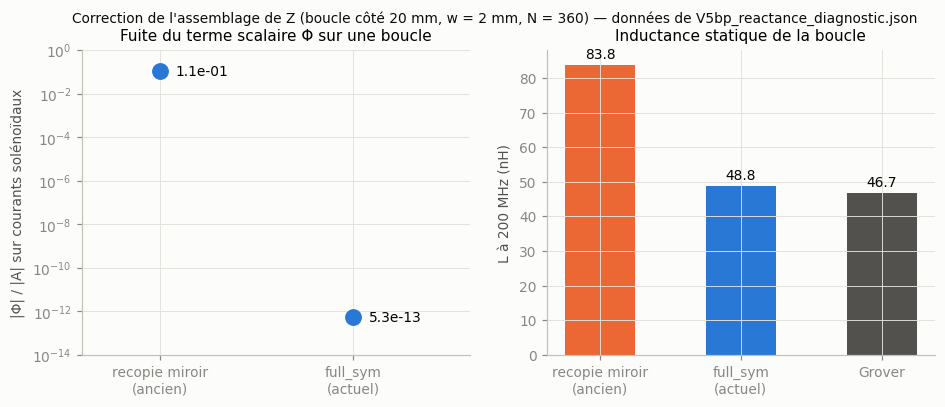

figure existante : V5bp_rin_eta_vs_w.png (copiée dans presentation/figures)


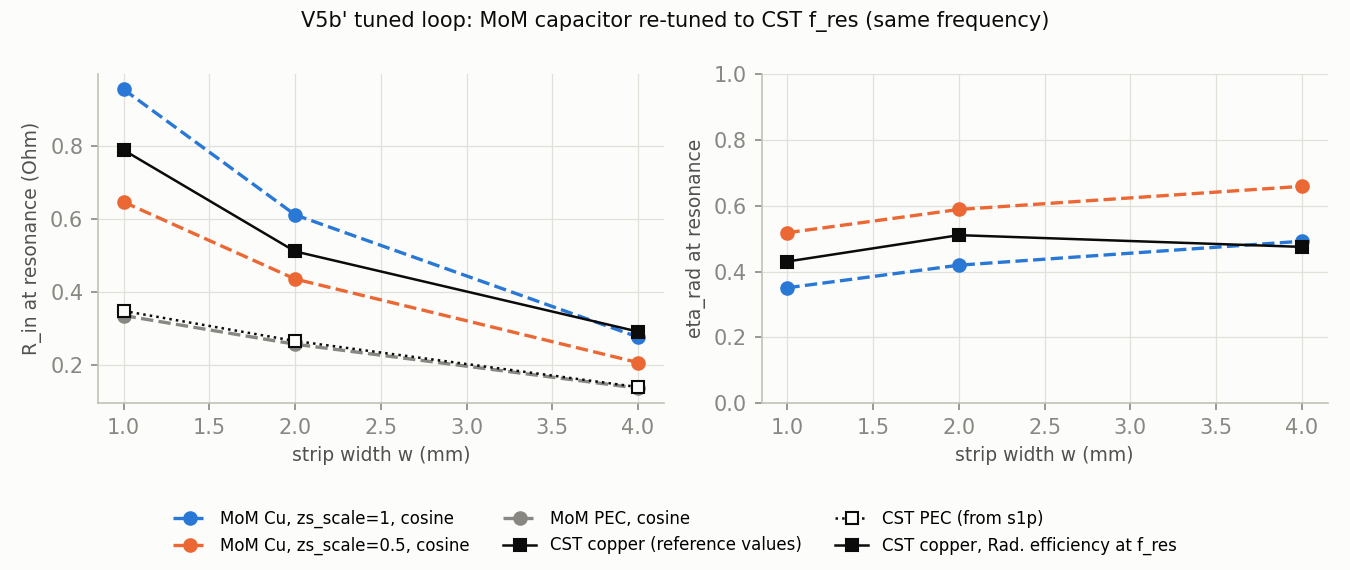

figure existante : V5bp_zin_w4mm.png (copiée dans presentation/figures)


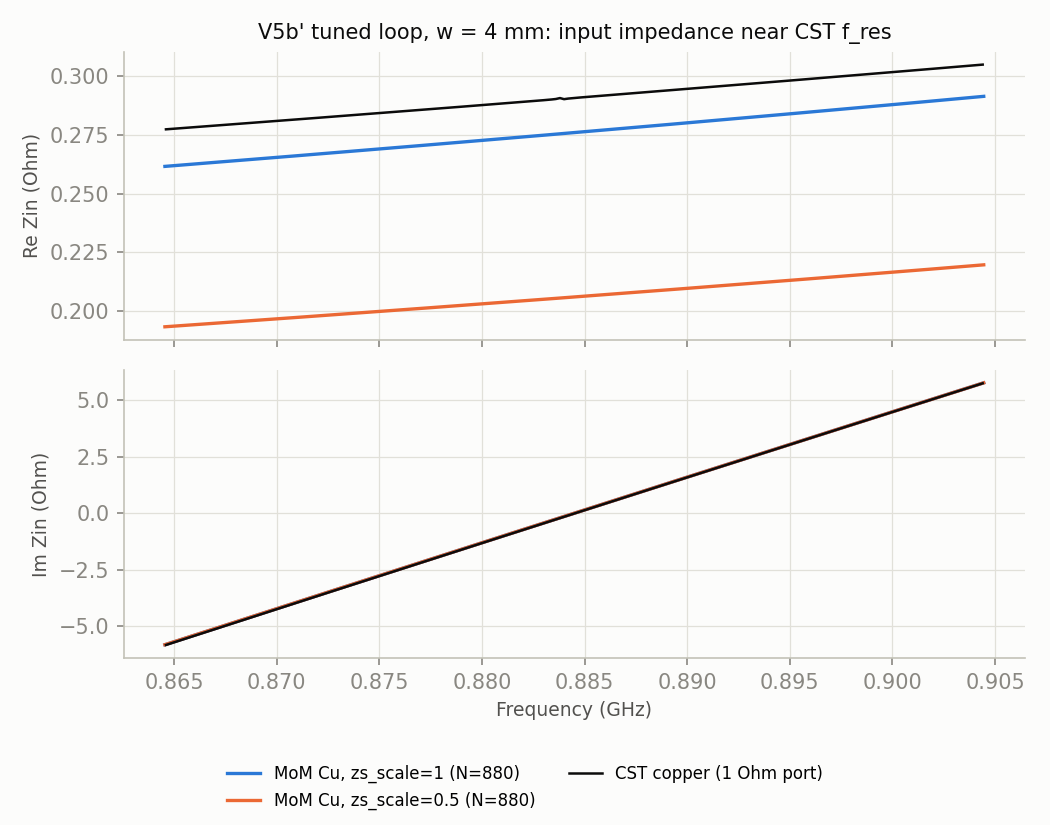

In [13]:
import compare_v5 as cv
from solver.optim.loss_model import alpha_calibrated

CST5 = cv.load_cst(V5_DIR)
MOM5 = {c['meta']['case']: c for c in cv.load_mom(V5_DIR / 'mom')}
DIAG = read_json(V5_DIR / 'figures' / 'V5bp_reactance_diagnostic.json')
VAL = []

# V5a: CST from its export; the MoM V5a sweep is not archived in resultats_V5/mom -> value quoted in the step-5 file
f5, z5 = CST5['V5a']['zin']
z_cst = z5[np.argmin(np.abs(f5 - 0.9e9))]
txt5 = (INSTR_DIR / 'etape5_modele_pertes_et_exploration.md').read_text(encoding='utf-8')
m = re.search(r'Z_in V5a passe à ([\d,]+) − j([\d,]+) Ω contre ([\d,]+) − j([\d,]+) Ω dans CST', txt5)
v5a_mom_cases = [c for c in cv.load_mom(V5_DIR / 'mom') if c['meta']['kind'] == 'V5a']
if m:
    z_mom = complex(float(m.group(1).replace(',', '.')), -float(m.group(2).replace(',', '.')))
    z_cst_md = complex(float(m.group(3).replace(',', '.')), -float(m.group(4).replace(',', '.')))
    check('V5a : Z_in CST cité (étape 5) vs export CST', z_cst_md, z_cst, 0.01, 'Ω')
    VAL.append(['V5a dipôle PEC 150 × 4 mm, Z_in à 0,9 GHz', 'port delta-gap et matrice Z',
                f'MoM {z_mom.real:.2f} {z_mom.imag:+.2f}j Ω contre CST {z_cst.real:.2f} {z_cst.imag:+.2f}j Ω : '
                f'Re {100 * (z_mom.real / z_cst.real - 1):+.1f} %, Im {z_mom.imag - z_cst.imag:+.1f} Ω '
                f'(port CST : edge port sur un gap de 0,5 mm) — *valeur MoM citée, balayage non archivé*'])
print(f'V5a : {len(v5a_mom_cases)} cas MoM archivés dans resultats_V5/mom')

# V5b': same geometry as CST (outer side 20 mm), coarse width mesh n_w = 4
cst_res = cv.cst_v5bp_resonances(CST5)
rows_bp = []
for w in (1.0, 2.0, 4.0):
    case = MOM5[f'V5bp_cst_w{w:g}mm_ns16_nw4_cosine']
    r = {(row['mode'], row['variant']): row for row in case['resonance']}
    f_cst_pec, r_cst_pec = cst_res[('pec', w)]
    f_cst_cu, r_cst_cu = cst_res[('cu', w)]
    r_rad = r[('C_tuned', 'PEC')]['R_in_exact_ohm']
    r_cond1 = r[('C_tuned', 'Cu_zs1')]['R_in_exact_ohm'] - r_rad
    a_cal = alpha_calibrated(w)
    eta_mom = r_rad / (r_rad + a_cal * r_cond1)
    eta_cst = cv.cst_rad_efficiency_v5bp(CST5, w, f_cst_cu)
    rows_bp.append(dict(w=w, f_mom=r[('C_cst', 'PEC')]['f_res_GHz'], f_cst=f_cst_pec / 1e9, r_mom=r_rad, r_cst=r_cst_pec,
                        eta_mom=eta_mom, eta_cst=eta_cst, a=a_cal))
md_table(['w (mm)', 'f_res PEC MoM / CST (GHz)', 'écart f_res', 'R_rad MoM / CST (Ω)', 'écart R_rad',
          'η MoM (α_cal) / CST', 'α_cal'],
         [[f"{r['w']:g}", f"{r['f_mom']:.4f} / {r['f_cst']:.4f}", f"{100 * (r['f_mom'] / r['f_cst'] - 1):+.2f} %",
           f"{r['r_mom']:.3f} / {r['r_cst']:.3f}", f"{100 * (r['r_mom'] / r['r_cst'] - 1):+.1f} %",
           f"{r['eta_mom']:.3f} / {r['eta_cst']:.3f}", f"{r['a']:.2f}"] for r in rows_bp])
VAL.append(["V5b′ petite boucle (côté extérieur 20 mm), PEC, à géométrie égale", 'réactance de boucle (f_res)',
            f"f_res : {min(100 * (r['f_mom'] / r['f_cst'] - 1) for r in rows_bp):+.2f} à "
            f"{max(100 * (r['f_mom'] / r['f_cst'] - 1) for r in rows_bp):+.2f} %"])
VAL.append(["V5b′, PEC, C retouchée à la f_res de CST", 'R_rad (partie réelle de Z, champ lointain)',
            f"{min(100 * (r['r_mom'] / r['r_cst'] - 1) for r in rows_bp):+.1f} à "
            f"{max(100 * (r['r_mom'] / r['r_cst'] - 1) for r in rows_bp):+.1f} %"])
VAL.append(["V5b′ cuivre", "pertes : α_cal(w)", f"η à {max(abs(r['eta_mom'] - r['eta_cst']) for r in rows_bp):.3f} près "
            "— *α_cal est calibré sur ces mêmes données : accord par construction, pas une validation indépendante*"])
d4 = DIAG['delta_and_ding']['ns16_nw4']
VAL.append(['Puissance rayonnée : intégrale sur la sphère vs ½ Iᴴ Re(Z) I', 'champ lointain exact (farfield.py)',
            f"écart relatif {abs(d4['R_rad_sphere'] / d4['R_rad_M'] - 1):.1e}"])
pc = DIAG['phi_cancellation_and_full_fill']['ns16_nw2']
lg = DIAG['references']['L_grover_nH']
f_low = min(pc['L_full_fill_sym_nH'], key=float)
VAL.append(["Correction de l'assemblage de Z (boucle, courant solénoïdal)", 'neutralité du terme Φ',
            f"Φ/A : {pc['phi_over_A_on_solenoidal']['mirrored (default)']:.3f} (recopie miroir) → "
            f"{pc['phi_over_A_on_solenoidal']['full fill, symmetrised']:.0e} (full_sym)"])
VAL.append([f'L statique de la boucle ({float(f_low) / 1e6:.0f} MHz) vs Grover', 'inductance (partie A)',
            f"miroir {pc['L_mirrored_nH'][f_low]:.1f} nH ({100 * (pc['L_mirrored_nH'][f_low] / lg - 1):+.0f} %) → "
            f"full_sym {pc['L_full_fill_sym_nH'][f_low]:.1f} nH ({100 * (pc['L_full_fill_sym_nH'][f_low] / lg - 1):+.1f} %), "
            f"Grover {lg:.1f} nH"])
md_table(['test', 'ce qu\'il valide', 'écart'], VAL)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
ax = axes[0]
labs = ['recopie miroir\n(ancien)', 'full_sym\n(actuel)']
leak = [pc['phi_over_A_on_solenoidal']['mirrored (default)'], pc['phi_over_A_on_solenoidal']['full fill, symmetrised']]
ax.plot([0, 1], leak, 'o', ms=10, color=SERIES[0])
for k, v in enumerate(leak):
    ax.text(k + 0.08, v, f'{v:.1e}', va='center')
ax.set_xticks([0, 1], labs); ax.set_xlim(-0.4, 1.6)
ax.set_yscale('log'); ax.set_ylim(1e-14, 1); ax.set_ylabel('|Φ| / |A| sur courants solénoïdaux')
ax.set_title('Fuite du terme scalaire Φ sur une boucle')
ax = axes[1]
ax.bar(labs + ['Grover'], [pc['L_mirrored_nH'][f_low], pc['L_full_fill_sym_nH'][f_low], lg],
       color=[SERIES[1], SERIES[0], INK_2], width=0.5)
for k, v in enumerate([pc['L_mirrored_nH'][f_low], pc['L_full_fill_sym_nH'][f_low], lg]):
    ax.text(k, v + 1, f'{v:.1f}', ha='center', va='bottom')
ax.set_ylabel(f'L à {float(f_low) / 1e6:.0f} MHz (nH)'); ax.set_title('Inductance statique de la boucle')
fig.suptitle(f"Correction de l'assemblage de Z (boucle côté {1e3 * DIAG['side_m']:g} mm, w = {1e3 * DIAG['width_m']:g} mm, "
             f"N = {pc['N']}) — données de V5bp_reactance_diagnostic.json", fontsize=9, color=INK)
save(fig, '09_correction_assemblage_Z.png')

for name in ('V5bp_rin_eta_vs_w.png', 'V5bp_zin_w4mm.png'):
    src = V5_DIR / 'figures' / name
    shutil.copy2(src, FIG_DIR / f'09_existante_{name}')
    FIGURES.append(f'09_existante_{name}')
    print(f'figure existante : {src.name} (copiée dans presentation/figures)')
    display(Image(filename=str(src), width=760))

Remarques : sur la figure `V5bp_rin_eta_vs_w.png`, les courbes MoM « Cu » sont tracées avec α = 1 et α = 0,5,
c'est-à-dire avant le calibrage α_cal(w) adopté à l'étape 5 ; le tableau ci-dessus donne η avec α_cal.
La figure existante `V5a_zin.png` ne contient que la courbe CST (le balayage MoM V5a n'est pas archivé) ;
elle n'est donc pas reprise ici.

## 10. Méthode

La matrice Z ne dépend que de la géométrie et de la fréquence : on la remplit **une fois**, puis on la réduit aux
3 ports (modèle multiport exact). Changer les charges, le port alimenté ou le réseau d'adaptation ne coûte plus
qu'une résolution 3 × 3, ce qui permet l'optimisation des charges, la recherche dans le kit et l'objectif robuste.
La géométrie (écarts entre rubans) est explorée sur une grille (B3) ou par optimisation bayésienne (B4).
Les temps ci-dessous sont **mesurés dans ce notebook** (section 3).

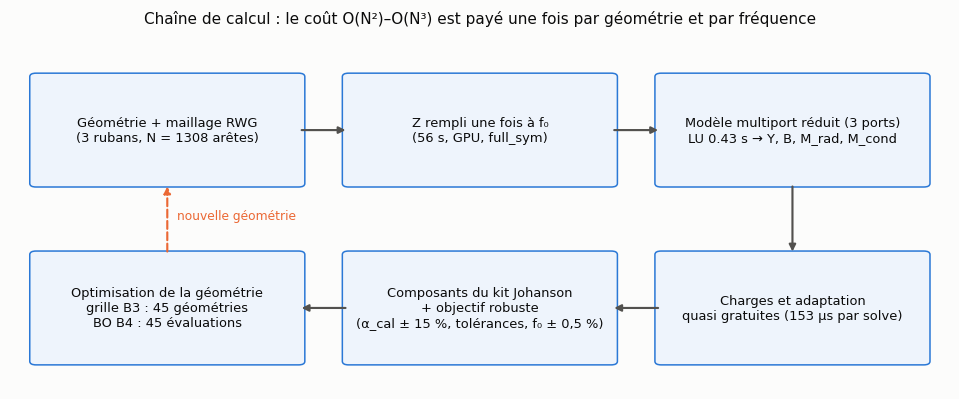

| étape (ce notebook, design B3) | temps mesuré |
|---|---|
| Gram G | 105 ms |
| remplissage de Z | 56.1 s |
| modèle réduit + opérateur champ lointain | 506 ms |
| LU de Z_t | 433 ms |
| précalcul B, Y, M_rad, M_cond | 52 ms |
| un solve (charges -> G, Z_in) | 153 µs |

Rapport remplissage / solve ≈ 4e+05 : c'est ce qui rend l'optimisation des charges et la recherche du réseau d'adaptation pratiquement gratuites. Pendant la campagne B3, le remplissage de Z a pris en moyenne 48 s par géométrie (2 fréquences, valeur lue dans `B3_designs.jsonl`). Recherche d'adaptation (étape 6b) : 261 389 combinaisons de composants évaluées sans aucun calcul MoM.

In [14]:
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.set_xlim(0, 3); ax.set_ylim(0, 2); ax.axis('off')
boxes = [
    (0.5, 1.45, f'Géométrie + maillage RWG\n(3 rubans, N = {mesh.n_edges} arêtes)'),
    (1.5, 1.45, f"Z rempli une fois à f₀\n({TIMES['remplissage de Z']:.0f} s, {'GPU' if GPU else 'CPU'}, full_sym)"),
    (2.5, 1.45, f"Modèle multiport réduit (3 ports)\nLU {TIMES['LU de Z_t']:.2f} s → Y, B, M_rad, M_cond"),
    (2.5, 0.45, f"Charges et adaptation\nquasi gratuites ({TIMES['un solve (charges -> G, Z_in)'] * 1e6:.0f} µs par solve)"),
    (1.5, 0.45, 'Composants du kit Johanson\n+ objectif robuste\n(α_cal ± 15 %, tolérances, f₀ ± 0,5 %)'),
    (0.5, 0.45, f'Optimisation de la géométrie\ngrille B3 : {len({(tuple(r["spacings_mm"])) for r in B3})} géométries\n'
                f'BO B4 : {len(B4_HIST["records"])} évaluations'),
]
for x, y, t in boxes:
    ax.add_patch(FancyBboxPatch((x - 0.42, y - 0.3), 0.84, 0.6, boxstyle='round,pad=0.02', fc='#eef4fc', ec=SERIES[0]))
    ax.text(x, y, t, ha='center', va='center', fontsize=8.5, color=INK)
arrow = dict(arrowstyle='-|>', color=INK_2, lw=1.4)
for (x0, y0), (x1, y1) in (((0.92, 1.45), (1.08, 1.45)), ((1.92, 1.45), (2.08, 1.45)), ((2.5, 1.15), (2.5, 0.75)),
                           ((2.08, 0.45), (1.92, 0.45)), ((1.08, 0.45), (0.92, 0.45))):
    ax.annotate('', xy=(x1, y1), xytext=(x0, y0), arrowprops=arrow)
ax.annotate('', xy=(0.5, 1.15), xytext=(0.5, 0.75), arrowprops=dict(arrowstyle='-|>', color=SERIES[1], lw=1.4, ls='--'))
ax.text(0.53, 0.95, 'nouvelle géométrie', color=SERIES[1], fontsize=8)
ax.set_title('Chaîne de calcul : le coût O(N²)–O(N³) est payé une fois par géométrie et par fréquence', color=INK)
save(fig, '10_methode.png')

md_table(['étape (ce notebook, design B3)', 'temps mesuré'],
         [[k, f'{v * 1e6:.0f} µs' if v < 1e-2 else (f'{v * 1e3:.0f} ms' if v < 1 else f'{v:.1f} s')] for k, v in TIMES.items()])
t_geo = np.mean([r['t_z_s'] for r in B3 if r['best_fed']])
n_comb = f"{sum(ADAPT['combinations_total'].values()):,}".replace(',', ' ')
display(Markdown(
    f"Rapport remplissage / solve ≈ {TIMES['remplissage de Z'] / TIMES['un solve (charges -> G, Z_in)']:.0e} : "
    f"c'est ce qui rend l'optimisation des charges et la recherche du réseau d'adaptation pratiquement gratuites. "
    f"Pendant la campagne B3, le remplissage de Z a pris en moyenne {t_geo:.0f} s par géométrie "
    f"(2 fréquences, valeur lue dans `B3_designs.jsonl`). Recherche d'adaptation (étape 6b) : "
    f"{n_comb} combinaisons de composants évaluées sans aucun calcul MoM."))

## 11. État et suite

Le tableau de statut est **tenu à la main** (dictionnaire `STATUT` ci-dessous) : à mettre à jour après chaque
résultat CST. La liste des fichiers déjà exportés dans `resultats_V6/V6a/` est lue sur le disque.

In [15]:
STATUT = {   # <- à mettre à jour à la main
    'V6a : modèle MoM dans CST (espace libre, gaps, capacités idéales)': 'exports CST présents, comparaison MoM à faire',
    'V6b : substrat réel': 'à faire',
    'V6c : alimentation réelle (balun, SMA) et réseau d\'adaptation': 'à faire',
    'Gel du design, Gerbers': 'dimanche 8/11 soir',
    'Fabrication (LEAT, au moins 2 exemplaires)': 'lundi 9/11 matin',
    'Mesure à Orb (S11, gain réalisé en fonction de l\'angle)': 'lundi 9/11 après-midi',
    'Rapport PDF': f'avant le {DEADLINE}',
}
md_table(['étape', 'statut'], [[k, v] for k, v in STATUT.items()])

v6a = sorted((V6_DIR / 'V6a').glob('*')) if (V6_DIR / 'V6a').is_dir() else []
md_table(['fichier CST dans resultats_V6/V6a', 'modifié le'],
         [[p.name, time.strftime('%d/%m/%Y %H:%M', time.localtime(p.stat().st_mtime))] for p in v6a] or [['(aucun)', '']])

esl_rk = ADAPT['esl_aware_rankings']
display(Markdown('\n'.join([
    '**Points ouverts**',
    '',
    f"- **ESL des capacités** : non relevée. Sur le réseau n° 1, ESL = 0,5 nH dégrade |S11| à "
    f"{fr(next(r['S11_dB'] for r in ADAPT['sensitivity'][0]['rows'] if 'ESL' in r['case'] and '0.5' in r['case']), 1)} dB ; "
    f"avec l'ESL connue, la même topologie reste la meilleure mais les valeurs changent "
    f"(ESL 1 nH : {esl_rk['1 nH'][0]['description']}).",
    f"- **Z_A de CST** : le seul raffinement du maillage MoM décale Z_A de "
    f"ΔR = {fr(ADAPT['antenna_data']['fine_mesh_shift_ohm'][0])} Ω et ΔX = {fr(ADAPT['antenna_data']['fine_mesh_shift_ohm'][1], 1)} Ω "
    f"(N = {PARAMS['mesh_check']['N_coarse']} → {PARAMS['mesh_check']['N_fine']}) ; le gap réel et le balun changeront davantage : "
    f"le réseau sera recalé sur le Z_A de CST (V6c).",
    '- **Substrat** : la permittivité du PCB abaisse les résonances des rubans et des parasites ; il faudra réaccorder '
    "les capacités de charge (ou la longueur) dans CST (V6b), car la bande n'est que d'environ 1 %.",
])))

| étape | statut |
|---|---|
| V6a : modèle MoM dans CST (espace libre, gaps, capacités idéales) | exports CST présents, comparaison MoM à faire |
| V6b : substrat réel | à faire |
| V6c : alimentation réelle (balun, SMA) et réseau d'adaptation | à faire |
| Gel du design, Gerbers | dimanche 8/11 soir |
| Fabrication (LEAT, au moins 2 exemplaires) | lundi 9/11 matin |
| Mesure à Orb (S11, gain réalisé en fonction de l'angle) | lundi 9/11 après-midi |
| Rapport PDF | avant le 10 novembre 2026 |

| fichier CST dans resultats_V6/V6a | modifié le |
|---|---|
| Reseau end-fire.s1p | 06/11/2026 15:20 |
| V6a.dxf | 06/11/2026 15:21 |
| V6a_farfield_cut_phi=0_f=1GHz.txt | 06/11/2026 15:23 |
| V6a_farfield_cut_phi=90_f=1GHz.txt | 06/11/2026 15:23 |
| V6a_farfield_cut_theta=90_f=1GHz.txt | 06/11/2026 15:23 |
| V6a_farfield_f=1GHz.txt | 06/11/2026 15:22 |
| V6a_Rad_Efficiency.txt | 06/11/2026 15:22 |
| V6a_Tot_Efficiency.txt | 06/11/2026 15:22 |
| V6a_Zin.txt | 06/11/2026 15:21 |

**Points ouverts**

- **ESL des capacités** : non relevée. Sur le réseau n° 1, ESL = 0,5 nH dégrade |S11| à -11,6 dB ; avec l'ESL connue, la même topologie reste la meilleure mais les valeurs changent (ESL 1 nH : shunt 2.2 pF (C 0402/0603, +-5%) | series 1 pF (C 0402/0603, +-10%) | series 1.2 pF (C 0402/0603, +-8%)).
- **Z_A de CST** : le seul raffinement du maillage MoM décale Z_A de ΔR = 0,57 Ω et ΔX = 11,5 Ω (N = 1308 → 2628) ; le gap réel et le balun changeront davantage : le réseau sera recalé sur le Z_A de CST (V6c).
- **Substrat** : la permittivité du PCB abaisse les résonances des rubans et des parasites ; il faudra réaccorder les capacités de charge (ou la longueur) dans CST (V6b), car la bande n'est que d'environ 1 %.

## 12. Contrôles de cohérence entre fichiers

Chaque valeur comparée vient de deux sources différentes (JSON, CSV, recalcul de ce notebook).
Une ligne marquée ✘ signale une incohérence à examiner.

In [16]:
md_table(['contrôle', 'écart', 'tolérance', ''],
         [[c['name'], f"{c['diff']:.2e} {c['unit']}", f"{c['tol']:g}", '✔' if c['ok'] else '**✘**'] for c in COHERENCE])
bad = [c for c in COHERENCE if not c['ok']]
print(f"{len(COHERENCE)} contrôles, {len(bad)} incohérence(s)" + (' : ' + '; '.join(c['name'] for c in bad) if bad else ''))
print(f'{len(FIGURES)} figures enregistrées dans {FIG_DIR} :')
for n in FIGURES:
    print('  ', n)
print(f'durée totale d\'exécution : {time.perf_counter() - T_START:.0f} s')

| contrôle | écart | tolérance |  |
|---|---|---|---|
| el1 : bords y = centre ± largeur/2 | 0.00e+00 mm | 1e-09 | ✔ |
| el1 : bords x = ± longueur/2 | 0.00e+00 mm | 1e-09 | ✔ |
| el2 : bords y = centre ± largeur/2 | 0.00e+00 mm | 1e-09 | ✔ |
| el2 : bords x = ± longueur/2 | 0.00e+00 mm | 1e-09 | ✔ |
| el3 : bords y = centre ± largeur/2 | 0.00e+00 mm | 1e-09 | ✔ |
| el3 : bords x = ± longueur/2 | 0.00e+00 mm | 1e-09 | ✔ |
| écarts JSON = différences des centres | 0.00e+00 mm | 1e-09 | ✔ |
| encombrement JSON = bord haut el3 − bord bas el1 | 0.00e+00 mm | 1e-09 | ✔ |
| réseau centré en y (centre des bords extrêmes = 0) | 0.00e+00 mm | 1e-09 | ✔ |
| el1 : valeur du kit = valeur du JSON | 0.00e+00 F | 1e-18 | ✔ |
| el3 : valeur du kit = valeur du JSON | 0.00e+00 F | 1e-18 | ✔ |
| maillage : centres y (mm) = JSON | 0.00e+00 mm | 1e-09 | ✔ |
| maillage : N = N du contrôle de maillage (JSON) | 0.00e+00  | 0 | ✔ |
| G recalculé vs JSON (G_kit) | 6.93e-14 dB | 0.001 | ✔ |
| Z_in recalculé vs JSON | 6.09e-12 Ω | 0.001 | ✔ |
| η recalculé vs JSON | 2.18e-14  | 1e-05 | ✔ |
| G_r(50 Ω) recalculé vs JSON | 2.74e-13 dB | 0.001 | ✔ |
| G recalculé vs CSV fréquence (f₀) | 1.71e-09 dB | 0.0001 | ✔ |
| G_φ recalculé vs CSV, coupe xy (θ = 90°), à 30 dB du max | 4.99e-07 dB | 0.001 | ✔ |
| G_φ recalculé vs CSV, coupe yz (φ = 90°), à 30 dB du max | 4.80e-08 dB | 0.001 | ✔ |
| F/B recalculé vs JSON | 4.19e-13 dB | 0.001 | ✔ |
| F/B : CSV coupe xy vs CSV fréquence (f₀) | 8.88e-16 dB | 0.001 | ✔ |
| G_φ(+y) recalculé vs G du JSON | 6.75e-14 dB | 0.001 | ✔ |
| adaptation : Z_A(f₀) vs paramètres | 1.52e-06 Ω | 0.0001 | ✔ |
| adaptation : G_A(f₀) vs paramètres | 1.71e-09 dB | 0.0001 | ✔ |
| adaptation : Q_in vs paramètres | 0.00e+00  | 1e-09 | ✔ |
| adaptation : G_r sans réseau vs paramètres | 4.26e-08 dB | 0.0001 | ✔ |
| G_r(50 Ω) CSV (f₀) vs paramètres | 4.45e-08 dB | 0.0001 | ✔ |
| Q_in : B3_checks.json vs paramètres | 0.00e+00  | 1e-09 | ✔ |
| B3_designs.jsonl (meilleur à 1 GHz) : écarts vs paramètres | 0.00e+00 mm | 1e-09 | ✔ |
| B3_designs.jsonl : G_kit vs paramètres | 0.00e+00 dB | 1e-09 | ✔ |
| B3_designs.jsonl : G robuste moyen vs paramètres | 0.00e+00 dB | 1e-09 | ✔ |
| B3_designs.jsonl : G_max vs paramètres | 0.00e+00 dB | 1e-09 | ✔ |
| B3_designs.jsonl : élément alimenté = paramètres | 0.00e+00  | 0 | ✔ |
| B3_designs.jsonl : charge el1 = composant des paramètres | 0.00e+00 F | 1e-18 | ✔ |
| B3_designs.jsonl : charge el3 = composant des paramètres | 0.00e+00 F | 1e-18 | ✔ |
| réseau n° 1 : positions du JSON = topologie | 0.00e+00  | 0 | ✔ |
| Monte-Carlo recalculé : G_r moyen vs JSON 6b | 0.00e+00 dB | 1e-06 | ✔ |
| Monte-Carlo recalculé : G_r P10 vs JSON 6b | 3.14e-08 dB | 1e-06 | ✔ |
| courbe G_r(f) recalculée vs JSON 6b | 1.60e-14 dB | 1e-06 | ✔ |
| V5a : Z_in CST cité (étape 5) vs export CST | 5.83e-03 Ω | 0.01 | ✔ |

41 contrôles, 0 incohérence(s)
16 figures enregistrées dans D:\PhD_Fahdilou_Leat\PUBLICATIONS\7-EurAAP Small Antenna Super-Gain Challenge\presentation\figures :
   01_challenge_boite_repere.png
   02_design_vue_dessus_cotes.png
   03_maillage_rwg_3d.png
   03_maillage_zoom_ports.png
   04_courants_surface_3d.png
   04_courant_le_long_des_rubans.png
   05_diagramme_3d_gain.png
   05_coupes_polaires_xy_yz.png
   06_G_D_eta_Zin_vs_f.png
   06_S11_Gr_avec_sans_reseau.png
   07_G_vs_nombre_elements.png
   08_robustesse.png
   09_correction_assemblage_Z.png
   09_existante_V5bp_rin_eta_vs_w.png
   09_existante_V5bp_zin_w4mm.png
   10_methode.png
durée totale d'exécution : 106 s
